# Comp1-传统组学

主要适配于传统组学的建模和刻画。典型的应用场景探究rad_score最最终临床诊断的作用。

数据的一般形式为(具体文件,文件夹名可以不同)：
1. `images`文件夹，存放研究对象所有的CT、MRI等数据。
2. `masks`文件夹, 存放手工（Manuelly）勾画的ROI区域。与images文件夹的文件意义对应。
3. `label.txt`文件，每个患者对应的标签，例如肿瘤的良恶性、5年存活状态等。

## Onekey步骤

1. 数据校验，检查数据格式是否正确。
2. 组学特征提取，如果第一步检查数据通过，则提取对应数据的特征。
3. 读取标注数据信息。
4. 特征与标注数据拼接。形成数据集。
5. 查看一些统计信息，检查数据时候存在异常点。
6. 正则化，将数据变化到服从 N~(0, 1)。
7. 通过相关系数，例如spearman、person等筛选出特征。
8. 构建训练集和测试集，这里使用的是随机划分，正常多中心验证，需要大家根据自己的场景构建两份数据。
9. 通过Lasso筛选特征，选取其中的非0项作为后续模型的特征。
10. 使用机器学习算法，例如LR、SVM、RF等进行任务学习。
11. 模型结果可视化，例如AUC、ROC曲线，混淆矩阵等。


In [1]:
## 获得视频教程
from onekey_algo.custom.Manager import onekey_show
onekey_show('传统组学任务')

[2026-06-28 23:54:00 - <frozen onekey_algo.custom.Manager>: 163]	INFO	播放视频功能已经设置成：Disable！


## 一、数据校验
首先需要检查诊断数据，如果显示`检查通过！`择可以正常运行之后的，否则请根据提示调整数据。

**注意**：这里要求images和masks文件夹中的文件名必须一一对应。e.g. `1.nii.gz`为images中的一个文件，在masks文件夹必须也存在一个`1.nii.gz`文件。

当然也可以使用自定义的函数，获取解析数据。

In [2]:
# 数据检验视频
onekey_show('传统组学任务|数据检验')

[2026-06-28 23:54:00 - <frozen onekey_algo.custom.Manager>: 163]	INFO	播放视频功能已经设置成：Disable！


### 指定数据

此模块有3个需要自己定义的参数

1. `mydir`: 数据存放的路径。
2. `labelf`: 每个样本的标注信息文件。
3. `labels`: 要让AI系统学习的目标，例如肿瘤的良恶性、T-stage等。

In [3]:
import os
from IPython.display import display
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
from onekey_algo import OnekeyDS as okds
from onekey_algo import get_param_in_cwd

os.makedirs('img', exist_ok=True)
os.makedirs('results', exist_ok=True)
os.makedirs('features', exist_ok=True)

# 设置任务Task前缀
task_type = 'INTRA'
# 设置数据目录
# mydir = r'你自己数据的路径'
mydir = get_param_in_cwd('radio_dir') or okds.ct
if mydir == okds.ct:
    print(f'正在使用Onekey数据：{okds.ct}，如果不符合预期，请修改目录位置！')
# 对应的标签文件
group_info = get_param_in_cwd('dataset_column') or 'group'
labelf = get_param_in_cwd('label_file') or os.path.join(mydir, 'label.csv')
# 读取标签数据列名
labels = [get_param_in_cwd('task_column') or 'label']

### images和masks匹配

这里要求images和masks文件夹中的文件名必须一一对应。e.g. `1.nii.gz`为images中的一个文件，在masks文件夹必须也存在一个`1.nii.gz`文件。

当然也可以使用自定义的函数，获取解析数据。

In [4]:
from pathlib import Path
from onekey_algo.custom.components.Radiology import diagnose_3d_image_mask_settings, get_image_mask_from_dir

# 生成images和masks对，一对一的关系。也可以自定义替换。
images, masks = get_image_mask_from_dir(mydir, images='images', masks='masks')

# 自定义获取images和masks数据的方法，下面的例子为，每个样本一个文件夹，图像是以im.nii结尾，mask是以seg.nii结尾。
# def get_images_mask(mydir):
#     images = []
#     masks = []
#     for root, dirs, files in os.walk(mydir):
#         for f in files:
#             if f.endswith('im.nii'):
#                 images.append(os.path.join(root, f))
#             if f.endswith('seg.nii'):
#                 masks.append(os.path.join(root, f))
#     return images, masks
# images, masks = get_images_mask(mydir)

diagnose_3d_image_mask_settings(images, masks)
print(f'获取到{len(images)}个样本。')

检查通过！
获取到30个样本。


# 传统组学特征

使用pyradiomics提取传统组学特征，正常这块不需要修改，下面是具体的Onekey封装的接口。

```python
def extract(self, images: Union[str, List[str]], 
            masks: Union[str, List[str]], labels: Union[int, List[int]] = 1, settings=None)
"""
    * images: List结构，待提取的图像列表。
    * masks: List结构，待提取的图像对应的mask，与Images必须一一对应。
    * labels: 提取标注为什么标签的特征。默认为提取label=1的。
    * settings: 其他提取特征的参数。默认为None。

"""
```

```python
def get_label_data_frame(self, label: int = 1, column_names=None, images='images', masks='labels')
"""
    * label: 获取对应label的特征。
    * columns_names: 默认为None，使用程序设定的列名即可。
"""
```
    
```python
def get_image_mask_from_dir(root, images='images', masks='labels')
"""
    * root: 待提取特征的目录。
    * images: root目录中原始数据的文件夹名。
    * masks: root目录中标注数据的文件夹名。
"""
```


In [5]:
# 特征提取视频
onekey_show('传统组学任务|特征提取')

[2026-06-28 23:54:19 - <frozen onekey_algo.custom.Manager>: 163]	INFO	播放视频功能已经设置成：Disable！


In [6]:
import warnings
import pandas as pd
 
warnings.filterwarnings("ignore")
from onekey_algo.custom.components.Radiology import ConventionalRadiomics

# 瘤内Mask ID
intra_mask_id = get_param_in_cwd('intra_mask_id') or 1

rad_data = []
# 如果要自定义一些特征提取方式，可以使用param_file。
# param_file = r'./custom_settings/exampleCT.yaml'
# extractor_settings这个参数放的是参数配置文件的位置，默认为空。
param_file = get_param_in_cwd('extractor_settings')
radiomics = ConventionalRadiomics(param_file, correctMask=True)

for prefix, mask_id in zip(['intra'], [intra_mask_id]):
    if os.path.exists(f'features/rad_features_{mask_id}.csv'):
        rad_data.append(pd.read_csv(f'features/rad_features_{mask_id}.csv', header=0))
    else:
        radiomics.extract(images, masks, labels=mask_id)
        feat_ = radiomics.get_label_data_frame(label=mask_id)
        feat_.columns = [f"{prefix}_{c.replace('-', '_')}" if c != 'ID' else c for c in feat_.columns]
        feat_.to_csv(f'features/rad_features_{mask_id}.csv', header=True, index=False)
        rad_data.append(feat_)
rad_data = rad_data[0]
rad_data

[2026-06-28 23:54:19 - <frozen onekey_algo.custom.components.Radiology>: 608]	INFO	使用E:\\1\\Onekey\\onekey_comp\\comp9-Solutions\\sol3. 传统组学-多中心-瘤内瘤周-临床\\custom_settings\\exampleCT.yaml的配置文件。
[2026-06-28 23:54:19 - core.py: 188]	INFO	validation.valid


,ID,intra_exponential_firstorder_10Percentile,intra_exponential_firstorder_90Percentile,intra_exponential_firstorder_Energy,intra_exponential_firstorder_Entropy,intra_exponential_firstorder_InterquartileRange,intra_exponential_firstorder_Mean,intra_exponential_firstorder_MeanAbsoluteDeviation,intra_exponential_firstorder_Median,intra_exponential_firstorder_Minimum,...,intra_wavelet_LLL_glszm_SizeZoneNonUniformityNormalized,intra_wavelet_LLL_glszm_SmallAreaEmphasis,intra_wavelet_LLL_glszm_SmallAreaHighGrayLevelEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,intra_wavelet_LLL_ngtdm_Coarseness,intra_wavelet_LLL_ngtdm_Complexity,intra_wavelet_LLL_ngtdm_Strength
0,1.nii.gz,64.053,160.135,1.805e+08,4.534,41.780,107.461,29.580,104.044,24.277,...,0.945,0.978,267985.531,0.007,6.768,0.966,0.048,0.011,1.397e+06,801.276
1,10.nii.gz,41.075,128.076,5.719e+08,4.671,45.421,81.968,27.692,78.668,12.479,...,0.943,0.978,358151.989,0.002,8.216,0.971,0.029,0.007,6.622e+06,1048.151
2,100.nii.gz,41.179,69.107,1.565e+08,3.159,14.964,57.188,9.234,58.672,23.564,...,0.929,0.972,238367.828,0.007,6.745,0.964,0.036,0.011,1.351e+06,651.391
3,101.nii.gz,48.285,106.545,1.087e+09,4.184,34.899,77.449,19.380,76.790,30.361,...,0.885,0.953,297578.298,0.001,8.313,0.931,0.145,0.006,3.340e+06,505.408
4,102.nii.gz,91.603,147.195,2.774e+07,3.114,32.277,122.673,18.977,119.219,91.603,...,1.000,1.000,294844.273,0.045,4.459,1.000,0.000,0.010,5.410e+05,1039.914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,95.nii.gz,28.265,56.779,3.383e+07,2.848,16.880,44.528,9.371,48.337,19.414,...,1.000,1.000,156275.000,0.032,4.890,1.000,0.000,0.016,2.804e+05,735.351
382,96.nii.gz,65.274,158.550,3.608e+08,4.724,44.006,110.768,31.298,104.291,35.652,...,0.903,0.961,282195.844,0.004,7.525,0.945,0.069,0.011,1.963e+06,657.505
383,97.nii.gz,46.251,82.420,1.099e+08,3.353,13.437,64.545,11.088,63.222,34.355,...,0.959,0.984,247329.858,0.011,6.372,0.979,0.021,0.012,1.191e+06,702.694
384,98.nii.gz,93.700,179.217,1.913e+08,4.465,48.765,132.727,26.177,129.236,23.892,...,0.987,0.995,288500.926,0.007,6.833,0.993,0.007,0.011,1.725e+06,703.145


## 特征统计

,0,count
1,firstorder,270
0,glcm,281
4,gldm,210
2,glrlm,238
3,glszm,232
5,ngtdm,66
6,shape,13


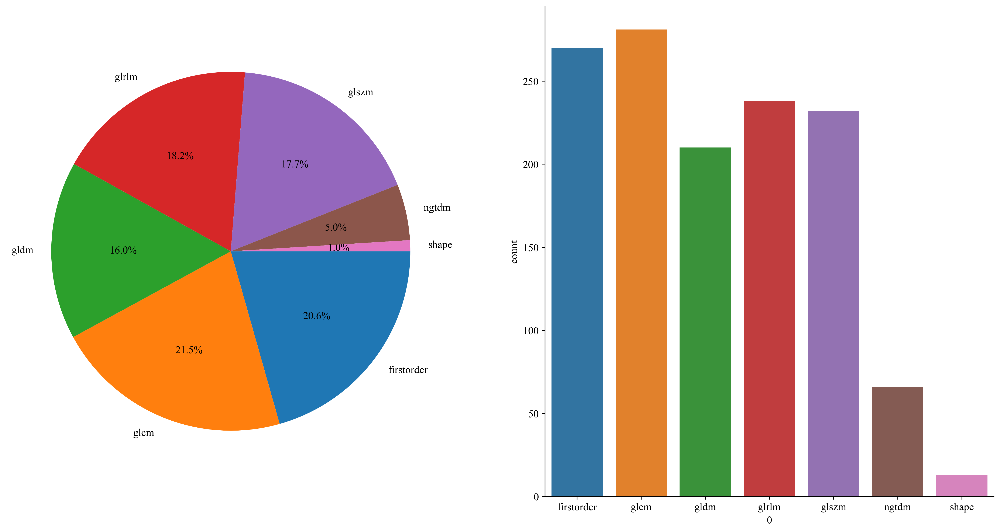

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sorted_counts = pd.DataFrame([c.split('_')[-2] for c in rad_data.columns if c !='ID']).value_counts()
sorted_counts = pd.DataFrame(sorted_counts, columns=['count']).reset_index()
sorted_counts = sorted_counts.sort_values(0)
display(sorted_counts)

plt.figure(figsize=(20, 10))
ax = plt.subplot(121)
plt.pie(sorted_counts['count'], labels=[i for i in sorted_counts[0]], startangle=0,
        counterclock = False, autopct = '%.1f%%')
# plt.bar_label(bar.containers[0])
ax = plt.subplot(122)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
bar = sns.barplot(data=sorted_counts, x=0, y='count', )
plt.savefig(f'img/{task_type}_feature_ratio.svg', bbox_inches = 'tight')

## 标注数据

数据以csv格式进行存储，这里如果是其他格式，可以使用自定义函数读取出每个样本的结果。

要求label_data为一个`DataFrame`格式，包括ID列以及后续的labels列，可以是多列，支持Multi-Task。

In [8]:
label_data = pd.read_csv(labelf)
label_data['ID'] = label_data['ID'].map(lambda x: f"{x}.nii.gz" if not (f"{x}".endswith('.nii.gz') or  f"{x}".endswith('.nii')) else x)
label_data = label_data[['ID', group_info] + labels]
label_data

,ID,group,label
0,176.nii.gz,train,0
1,147.nii.gz,train,0
2,305.nii.gz,train,0
3,27.nii.gz,train,0
4,345.nii.gz,train,0
...,...,...,...
381,212.nii.gz,test,0
382,39.nii.gz,test,0
383,126.nii.gz,test,0
384,244.nii.gz,val,0


## 特征拼接 

将标注数据`label_data`与`rad_data`进行合并，得到训练数据。

**注意：** 
1. 需要删掉ID这一列
2. 如果发现数据少了，需要自行检查数据是否匹配。

In [9]:
from onekey_algo.custom.utils import print_join_info

print_join_info(rad_data, label_data)
combined_data = pd.merge(rad_data, label_data, on=['ID'], how='inner')
ids = combined_data['ID']
combined_data = combined_data.drop(['ID'], axis=1)
print(combined_data[labels].value_counts())
combined_data

[2026-06-28 23:54:21 - <frozen onekey_algo.custom.utils>:  60]	INFO	ID特征完全匹配！


label
0        348
1         38
dtype: int64


,intra_exponential_firstorder_10Percentile,intra_exponential_firstorder_90Percentile,intra_exponential_firstorder_Energy,intra_exponential_firstorder_Entropy,intra_exponential_firstorder_InterquartileRange,intra_exponential_firstorder_Mean,intra_exponential_firstorder_MeanAbsoluteDeviation,intra_exponential_firstorder_Median,intra_exponential_firstorder_Minimum,intra_exponential_firstorder_RobustMeanAbsoluteDeviation,...,intra_wavelet_LLL_glszm_SmallAreaHighGrayLevelEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,intra_wavelet_LLL_ngtdm_Coarseness,intra_wavelet_LLL_ngtdm_Complexity,intra_wavelet_LLL_ngtdm_Strength,group,label
0,64.053,160.135,1.805e+08,4.534,41.780,107.461,29.580,104.044,24.277,21.378,...,267985.531,0.007,6.768,0.966,0.048,0.011,1.397e+06,801.276,train,0
1,41.075,128.076,5.719e+08,4.671,45.421,81.968,27.692,78.668,12.479,19.494,...,358151.989,0.002,8.216,0.971,0.029,0.007,6.622e+06,1048.151,train,0
2,41.179,69.107,1.565e+08,3.159,14.964,57.188,9.234,58.672,23.564,6.354,...,238367.828,0.007,6.745,0.964,0.036,0.011,1.351e+06,651.391,train,0
3,48.285,106.545,1.087e+09,4.184,34.899,77.449,19.380,76.790,30.361,14.551,...,297578.298,0.001,8.313,0.931,0.145,0.006,3.340e+06,505.408,train,0
4,91.603,147.195,2.774e+07,3.114,32.277,122.673,18.977,119.219,91.603,16.069,...,294844.273,0.045,4.459,1.000,0.000,0.010,5.410e+05,1039.914,train,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,28.265,56.779,3.383e+07,2.848,16.880,44.528,9.371,48.337,19.414,7.597,...,156275.000,0.032,4.890,1.000,0.000,0.016,2.804e+05,735.351,val,0
382,65.274,158.550,3.608e+08,4.724,44.006,110.768,31.298,104.291,35.652,19.740,...,282195.844,0.004,7.525,0.945,0.069,0.011,1.963e+06,657.505,train,0
383,46.251,82.420,1.099e+08,3.353,13.437,64.545,11.088,63.222,34.355,7.198,...,247329.858,0.011,6.372,0.979,0.021,0.012,1.191e+06,702.694,test,0
384,93.700,179.217,1.913e+08,4.465,48.765,132.727,26.177,129.236,23.892,18.163,...,288500.926,0.007,6.833,0.993,0.007,0.011,1.725e+06,703.145,val,0


## 获取到数据的统计信息

1. count，统计样本个数。
2. mean、std, 对应特征的均值、方差
3. min, 25%, 50%, 75%, max，对应特征的最小值，25,50,75分位数，最大值。

In [10]:
combined_data.describe()

,intra_exponential_firstorder_10Percentile,intra_exponential_firstorder_90Percentile,intra_exponential_firstorder_Energy,intra_exponential_firstorder_Entropy,intra_exponential_firstorder_InterquartileRange,intra_exponential_firstorder_Mean,intra_exponential_firstorder_MeanAbsoluteDeviation,intra_exponential_firstorder_Median,intra_exponential_firstorder_Minimum,intra_exponential_firstorder_RobustMeanAbsoluteDeviation,...,intra_wavelet_LLL_glszm_SmallAreaEmphasis,intra_wavelet_LLL_glszm_SmallAreaHighGrayLevelEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,intra_wavelet_LLL_ngtdm_Coarseness,intra_wavelet_LLL_ngtdm_Complexity,intra_wavelet_LLL_ngtdm_Strength,label
count,386.000,386.000,3.860e+02,3.860e+02,386.000,386.000,386.000,386.000,386.000,386.000,...,386.000,3.860e+02,3.860e+02,386.000,386.000,386.000,386.000,3.860e+02,386.000,386.000
mean,49.832,109.838,3.545e+08,3.561e+00,29.988,80.999,24.900,74.116,33.459,13.145,...,0.980,2.867e+05,1.496e-02,6.607,0.969,10.291,0.009,2.669e+06,913.501,0.098
std,118.164,127.947,8.271e+08,8.643e-01,25.421,120.810,36.858,118.212,119.311,10.840,...,0.021,1.740e+05,2.124e-02,1.279,0.061,181.016,0.002,2.395e+06,335.683,0.298
min,5.107,20.019,6.719e+06,-3.203e-16,0.000,14.562,0.000,13.081,0.195,0.000,...,0.784,1.054e+04,2.663e-04,2.585,0.220,0.000,0.003,8.998e+03,80.379,0.000
25%,28.267,64.518,6.412e+07,3.045e+00,15.645,48.400,9.759,46.936,12.666,6.863,...,0.970,1.794e+05,3.444e-03,5.720,0.960,0.006,0.007,1.188e+06,691.644,0.000
50%,38.178,83.903,1.496e+08,3.554e+00,23.030,60.868,15.202,57.551,21.234,9.995,...,0.983,2.500e+05,8.026e-03,6.735,0.977,0.023,0.008,2.011e+06,868.534,0.000
75%,47.423,114.471,3.530e+08,4.103e+00,34.692,80.189,25.518,75.510,30.667,15.605,...,0.996,3.547e+05,1.780e-02,7.577,0.994,0.044,0.010,3.313e+06,1089.460,0.000
max,1584.963,1584.963,1.301e+10,6.196e+00,189.432,1584.963,364.127,1584.963,1584.963,82.052,...,1.000,1.416e+06,1.668e-01,9.308,1.000,3540.864,0.021,1.906e+07,2603.301,1.000


## Z-score

`normalize_df` 为onekey中正则化的API，将数据变化到0均值1方差。正则化的方法为

$column = \frac{column - mean}{std}$

In [11]:
from onekey_algo.custom.components.comp1 import normalize_df
data = normalize_df(combined_data, not_norm=labels, group=group_info)
data = data.dropna(axis=1)
data.describe()

,intra_exponential_firstorder_10Percentile,intra_exponential_firstorder_90Percentile,intra_exponential_firstorder_Energy,intra_exponential_firstorder_Entropy,intra_exponential_firstorder_InterquartileRange,intra_exponential_firstorder_Mean,intra_exponential_firstorder_MeanAbsoluteDeviation,intra_exponential_firstorder_Median,intra_exponential_firstorder_Minimum,intra_exponential_firstorder_RobustMeanAbsoluteDeviation,...,intra_wavelet_LLL_glszm_SmallAreaEmphasis,intra_wavelet_LLL_glszm_SmallAreaHighGrayLevelEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,intra_wavelet_LLL_ngtdm_Coarseness,intra_wavelet_LLL_ngtdm_Complexity,intra_wavelet_LLL_ngtdm_Strength,label
count,3.860e+02,3.860e+02,3.860e+02,386.000,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,...,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,3.860e+02,386.000
mean,9.204e-17,-4.487e-17,-6.903e-18,0.000,3.682e-17,-1.841e-17,-2.301e-17,1.381e-17,-3.682e-17,-2.301e-17,...,-2.979e-15,-7.478e-17,8.053e-18,-1.312e-16,2.499e-15,-6.903e-18,-7.133e-17,-1.381e-16,-9.664e-17,0.098
std,9.974e-01,9.974e-01,9.974e-01,0.997,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,...,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,9.974e-01,0.298
min,-2.023e+00,-1.486e+00,-5.893e-01,-3.736,-1.141e+00,-1.449e+00,-9.123e-01,-1.957e+00,-1.771e+00,-1.163e+00,...,-7.897e+00,-1.734e+00,-8.164e-01,-3.247e+00,-8.621e+00,-1.058e+00,-2.525e+00,-1.267e+00,-2.442e+00,0.000
25%,-2.543e-01,-4.302e-01,-3.625e-01,-0.589,-5.802e-01,-3.791e-01,-4.115e-01,-3.617e-01,-2.785e-01,-5.748e-01,...,-4.478e-01,-6.212e-01,-5.400e-01,-6.823e-01,-2.240e-01,-2.898e-01,-6.612e-01,-6.132e-01,-6.484e-01,0.000
50%,-1.371e-01,-2.333e-01,-2.607e-01,-0.003,-2.687e-01,-1.941e-01,-2.645e-01,-1.790e-01,-1.410e-01,-2.984e-01,...,1.692e-01,-2.119e-01,-3.402e-01,1.053e-01,1.633e-01,-8.475e-02,-1.703e-01,-2.740e-01,-1.132e-01,0.000
75%,7.373e-02,8.408e-02,4.389e-03,0.611,1.972e-01,4.853e-02,6.544e-03,8.091e-02,5.285e-02,2.101e-01,...,8.317e-01,3.623e-01,1.077e-01,7.620e-01,4.109e-01,-8.432e-02,5.419e-01,2.757e-01,5.200e-01,0.000
max,8.696e+00,8.204e+00,1.189e+01,2.853,5.366e+00,8.565e+00,7.574e+00,8.625e+00,8.693e+00,5.611e+00,...,1.276e+00,5.651e+00,7.541e+00,2.142e+00,1.264e+00,1.302e+01,5.304e+00,6.051e+00,5.020e+00,1.000


## 统计检验

通过ttest或者utest进行特征筛选。

**注意** ：此步骤不是论文的标配，所以用不用在自己的选择，可以通过修改pvalue的值进行调整，默认是0.05为显著。

In [12]:
import seaborn as sns
from onekey_algo.custom.components.stats import clinic_stats

stats = clinic_stats(data[data['group'] == 'train'], stats_columns=list(data.columns[0:-2]), label_column=labels[0], 
                     continuous_columns=list(data.columns[0:-2]))
stats

,feature_name,-label=ALL,-label=0,-label=1,pvalue
0,intra_exponential_firstorder_10Percentile,-0.00±1.00,-0.04±0.79,0.33±2.09,0.063
1,intra_exponential_firstorder_90Percentile,-0.00±1.00,-0.05±0.80,0.42±2.02,0.326
2,intra_exponential_firstorder_Energy,0.00±1.00,-0.12±0.33,1.03±2.81,<0.001
3,intra_exponential_firstorder_Entropy,-0.00±1.00,-0.03±0.95,0.27±1.39,0.059
4,intra_exponential_firstorder_InterquartileRange,0.00±1.00,-0.03±0.95,0.24±1.39,0.228
...,...,...,...,...,...
1305,intra_wavelet_LLL_glszm_ZonePercentage,-0.00±1.00,0.06±0.79,-0.54±2.04,0.003
1306,intra_wavelet_LLL_glszm_ZoneVariance,0.00±1.00,-0.07±0.10,0.64±3.09,0.004
1307,intra_wavelet_LLL_ngtdm_Coarseness,-0.00±1.00,0.05±1.00,-0.46±0.92,0.121
1308,intra_wavelet_LLL_ngtdm_Complexity,-0.00±1.00,-0.06±0.89,0.50±1.63,0.146


#### 输出特征分布的图

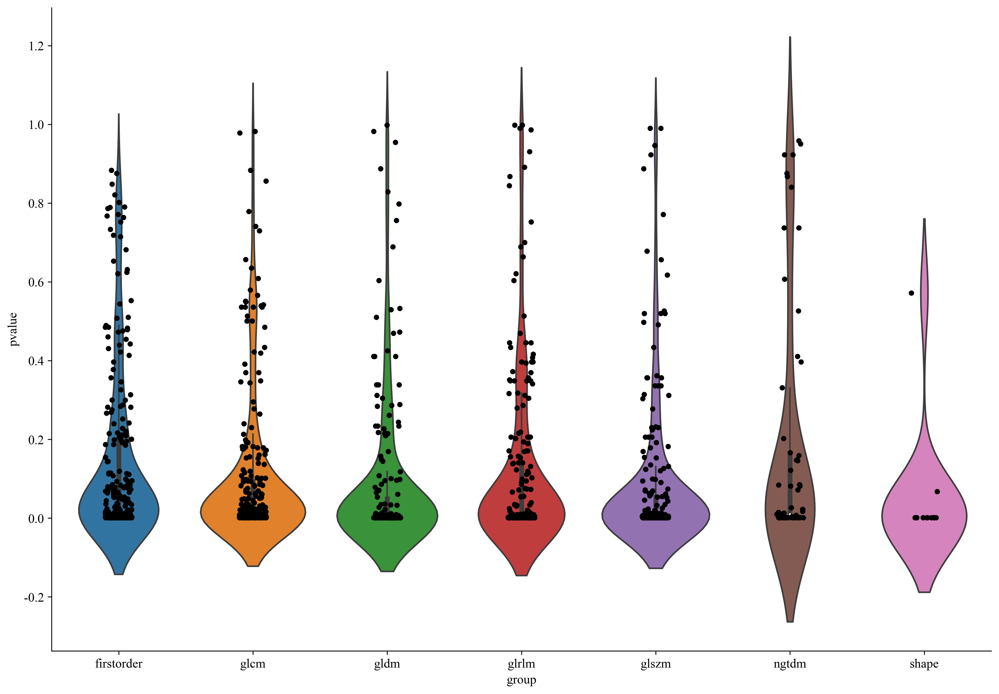

In [13]:
import matplotlib.pyplot as plt

def map2float(x):
    try:
        return float(str(x)[1:])
    except:
        return 1

stats[['pvalue']] = stats[['pvalue']].applymap(map2float)
stats[['group']] = stats[['feature_name']].applymap(lambda x: x.split('_')[-2])
stats = stats[['feature_name', 'pvalue', 'group']]
g = sns.catplot(x="group", y="pvalue", data=stats, kind="violin")
g.fig.set_size_inches(15,10)
sns.stripplot(x="group", y="pvalue", data=stats, ax=g.ax, color='black')
plt.savefig(f'img/{task_type}_feature_stats.svg', bbox_inches = 'tight')

#### 调整pvalue进行筛选。

In [14]:
pvalue = 0.05
sel_feature = list(stats[stats['pvalue'] < pvalue]['feature_name']) + labels + [group_info]
data = data[sel_feature]
data

,intra_exponential_firstorder_Energy,intra_exponential_firstorder_TotalEnergy,intra_exponential_glcm_Imc1,intra_exponential_glcm_JointEnergy,intra_exponential_glcm_JointEntropy,intra_exponential_glcm_MaximumProbability,intra_exponential_glcm_SumEntropy,intra_exponential_gldm_DependenceEntropy,intra_exponential_gldm_DependenceNonUniformity,intra_exponential_gldm_DependenceVariance,...,intra_wavelet_LLL_glszm_LowGrayLevelZoneEmphasis,intra_wavelet_LLL_glszm_SizeZoneNonUniformity,intra_wavelet_LLL_glszm_SizeZoneNonUniformityNormalized,intra_wavelet_LLL_glszm_SmallAreaEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,label,group
5,-0.535,-0.535,-0.665,1.219,-1.449,1.126,-1.532,-1.300,-0.549,-0.705,...,8.344e-01,-0.678,1.126,1.089,8.344e-01,-1.311,1.049,-0.837,0,test
7,-0.399,-0.399,-0.980,-0.408,0.097,-0.570,0.435,-0.289,-0.269,-0.735,...,-1.483e-01,-0.497,-0.484,-0.438,-1.483e-01,-0.196,-0.350,0.099,0,test
8,-0.415,-0.415,-0.400,-0.381,0.055,-0.466,0.230,-0.182,-0.354,-0.195,...,-9.028e-02,-0.528,-1.169,-1.122,-9.029e-02,-0.383,-0.948,0.497,0,test
22,2.154,2.154,1.230,-0.284,0.305,0.157,0.323,1.256,0.385,2.361,...,-6.409e-01,1.922,-1.617,-1.668,-6.409e-01,1.016,-1.843,1.893,1,test
25,-0.564,-0.564,-2.506,2.397,-1.877,2.078,-2.108,-1.530,-0.579,-0.929,...,2.049e+00,-0.728,1.126,1.089,2.049e+00,-1.976,1.049,-0.837,0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,-0.433,-0.433,-0.061,-0.110,-0.441,-0.090,-0.425,-0.748,-0.442,-0.335,...,7.534e-03,-0.421,1.309,1.276,7.562e-03,-0.534,1.264,-1.058,0,val
379,-0.426,-0.426,0.385,0.062,-0.571,0.315,-0.565,-0.417,-0.506,-0.246,...,-5.886e-04,-0.423,0.663,0.675,-5.627e-04,-0.375,0.687,-0.656,1,val
381,-0.499,-0.499,-1.033,0.516,-1.049,0.376,-1.065,-1.449,-0.466,-0.978,...,1.036e+00,-0.506,1.309,1.276,1.036e+00,-1.335,1.264,-1.058,0,val
384,-0.253,-0.253,-0.334,-0.649,0.775,-0.769,1.007,0.559,-0.139,-0.576,...,-4.401e-01,-0.248,1.001,0.992,-4.401e-01,0.170,0.989,-0.866,0,val


### 相关系数

计算相关系数的方法有3种可供选择
1. pearson （皮尔逊相关系数）: standard correlation coefficient

2. kendall (肯德尔相关性系数) : Kendall Tau correlation coefficient

3. spearman (斯皮尔曼相关性系数): Spearman rank correlation

三种相关系数参考：https://blog.csdn.net/zmqsdu9001/article/details/82840332

In [15]:
# 相关系数视频
onekey_show('传统组学任务|相关系数')

[2026-06-28 23:54:37 - <frozen onekey_algo.custom.Manager>: 163]	INFO	播放视频功能已经设置成：Disable！


In [16]:
pearson_corr = data[data['group'] == 'train'][[c for c in data.columns if c not in labels]].corr('pearson')
# kendall_corr = data[[c for c in data.columns if c not in labels]].corr('kendall')
# spearman_corr = data[[c for c in data.columns if c not in labels]].corr('spearman')

### 相关系数可视化

通过修改变量名，可以可视化不同相关系数下的相关矩阵。

**注意**：当特征特别多的时候（大于100），尽量不要可视化，否则运行时间会特别长。

In [17]:
import seaborn as sns
from onekey_algo.custom.components.comp1 import draw_matrix

if data.shape[0] < 100:
    plt.figure(figsize=(50.0, 40.0))

    # 选择可视化的相关系数
    draw_matrix(pearson_corr, annot=True, cmap='YlGnBu', cbar=False)
    plt.savefig(f'img/{task_type}_feature_corr.svg', bbox_inches = 'tight')

### 聚类分析

通过修改变量名，可以可视化不同相关系数下的相聚类分析矩阵。

注意：当特征特别多的时候（大于100），尽量不要可视化，否则运行时间会特别长。

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

if data.shape[0] < 100:
    pp = sns.clustermap(pearson_corr, linewidths=.5, figsize=(50.0, 40.0), cmap='YlGnBu')
    plt.setp(pp.ax_heatmap.get_yticklabels(), rotation=0)
    plt.savefig(f'img/{task_type}_feature_cluster.svg', bbox_inches = 'tight')

### 特征筛选 -- 相关系数

根据相关系数，对于相关性比较高的特征（一般文献取corr>0.9），两者保留其一。

```python
def select_feature(corr, threshold: float = 0.9, keep: int = 1, topn=10, verbose=False):
    """
    * corr, 相关系数矩阵。
    * threshold，筛选的相关系数的阈值，大于阈值的两者保留其一（可以根据keep修改，可以是其二...）。默认阈值为0.9
    * keep，可以选择大于相关系数，保留几个，默认只保留一个。
    * topn, 每次去掉多少重复特征。
    * verbose，是否打印日志
    """
```

In [19]:
# 特征筛选视频
onekey_show('传统组学任务|特征筛选')

[2026-06-28 23:54:38 - <frozen onekey_algo.custom.Manager>: 163]	INFO	播放视频功能已经设置成：Disable！


In [20]:
import math
from onekey_algo.custom.components.comp1 import select_feature, select_feature_mrmr

sel_feature = select_feature(pearson_corr, threshold=0.9, topn=256, verbose=False)
if get_param_in_cwd('mrmr_sel_feature_num') is not None:
    sel_feature = select_feature_mrmr(data[data['group'] == 'train'][sel_feature + labels], 
                                      num_features=get_param_in_cwd('mrmr_sel_feature_num'))
sel_feature += labels + [group_info]
sel_feature

['intra_exponential_gldm_DependenceVariance',
 'intra_exponential_glrlm_RunEntropy',
 'intra_exponential_glszm_SizeZoneNonUniformity',
 'intra_exponential_glszm_SmallAreaLowGrayLevelEmphasis',
 'intra_gradient_firstorder_RootMeanSquared',
 'intra_gradient_glcm_ClusterProminence',
 'intra_gradient_glcm_DifferenceVariance',
 'intra_gradient_gldm_LargeDependenceHighGrayLevelEmphasis',
 'intra_gradient_glszm_GrayLevelVariance',
 'intra_gradient_glszm_SmallAreaEmphasis',
 'intra_gradient_glszm_SmallAreaHighGrayLevelEmphasis',
 'intra_gradient_ngtdm_Coarseness',
 'intra_gradient_ngtdm_Strength',
 'intra_log_sigma_1_0_mm_3D_firstorder_10Percentile',
 'intra_log_sigma_1_0_mm_3D_glcm_DifferenceVariance',
 'intra_log_sigma_1_0_mm_3D_glszm_SmallAreaEmphasis',
 'intra_log_sigma_1_0_mm_3D_glszm_SmallAreaLowGrayLevelEmphasis',
 'intra_log_sigma_1_0_mm_3D_ngtdm_Coarseness',
 'intra_log_sigma_1_0_mm_3D_ngtdm_Strength',
 'intra_log_sigma_2_0_mm_3D_firstorder_10Percentile',
 'intra_log_sigma_2_0_mm_3D_f

### 过滤特征

通过`sel_feature`过滤出筛选出来的特征。

In [21]:
sel_data = data[sel_feature]
sel_data

,intra_exponential_gldm_DependenceVariance,intra_exponential_glrlm_RunEntropy,intra_exponential_glszm_SizeZoneNonUniformity,intra_exponential_glszm_SmallAreaLowGrayLevelEmphasis,intra_gradient_firstorder_RootMeanSquared,intra_gradient_glcm_ClusterProminence,intra_gradient_glcm_DifferenceVariance,intra_gradient_gldm_LargeDependenceHighGrayLevelEmphasis,intra_gradient_glszm_GrayLevelVariance,intra_gradient_glszm_SmallAreaEmphasis,...,intra_wavelet_LLL_glrlm_GrayLevelNonUniformityNormalized,intra_wavelet_LLL_glszm_GrayLevelNonUniformity,intra_wavelet_LLL_glszm_SizeZoneNonUniformity,intra_wavelet_LLL_glszm_SmallAreaEmphasis,intra_wavelet_LLL_glszm_SmallAreaLowGrayLevelEmphasis,intra_wavelet_LLL_glszm_ZoneEntropy,intra_wavelet_LLL_glszm_ZonePercentage,intra_wavelet_LLL_glszm_ZoneVariance,label,group
5,-0.705,-1.348,-0.344,1.321,1.020,-0.495,-0.053,-0.322,0.267,2.787,...,0.773,-0.581,-0.678,1.089,8.344e-01,-1.311,1.049,-0.837,0,test
7,-0.735,0.362,-0.229,-0.363,0.451,-0.581,-0.174,-0.070,-0.216,1.043,...,-0.192,-0.515,-0.497,-0.438,-1.483e-01,-0.196,-0.350,0.099,0,test
8,-0.195,0.095,-0.308,0.616,-1.051,-0.952,-1.159,-1.093,-1.109,0.356,...,-0.056,-0.390,-0.528,-1.122,-9.029e-02,-0.383,-0.948,0.497,0,test
22,2.361,0.351,0.152,-0.187,-1.251,0.433,-0.380,-0.536,0.222,-1.434,...,-0.462,4.004,1.922,-1.668,-6.409e-01,1.016,-1.843,1.893,1,test
25,-0.929,-1.131,-0.530,2.434,2.229,1.467,1.160,2.491,3.216,0.394,...,2.019,-0.581,-0.728,1.089,2.049e+00,-1.976,1.049,-0.837,0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,-0.335,-0.527,-0.399,0.054,1.363,0.046,0.722,0.308,0.818,1.682,...,0.054,-0.328,-0.421,1.276,7.562e-03,-0.534,1.264,-1.058,0,val
379,-0.246,-0.771,-0.515,-0.129,0.956,0.580,1.695,1.464,1.626,0.280,...,-0.121,-0.440,-0.423,0.675,-5.627e-04,-0.375,0.687,-0.656,1,val
381,-0.978,-1.221,-0.528,-0.011,-0.848,-0.572,-1.264,-0.833,-0.843,-2.498,...,1.052,-0.405,-0.506,1.276,1.036e+00,-1.335,1.264,-1.058,0,val
384,-0.576,1.062,-0.113,-0.405,-0.286,1.920,0.572,0.105,0.653,-0.863,...,-0.399,-0.200,-0.248,0.992,-4.401e-01,0.170,0.989,-0.866,0,val


### 样本可视化

根据特征和label信息，将rad features降维到2维，看不同的label样本在二维空间的分布。

**注意**：由于特征空间维度极高，降维难免会有损失，所以二维的可视化仅供参考。

目前支持的:

| **降维方法** | **Method名称**                                                 |
| ------------ | ------------------------------------------------------------ |
| LLE      | Standard LLE, Modified LLE                                   |
| PCA      | t-SNE, NCA                                                      |
| SVD      | Truncated SVD                                              |
| Model Based      | Random projection, Isomap, MDS, Random Trees,Spectral       |

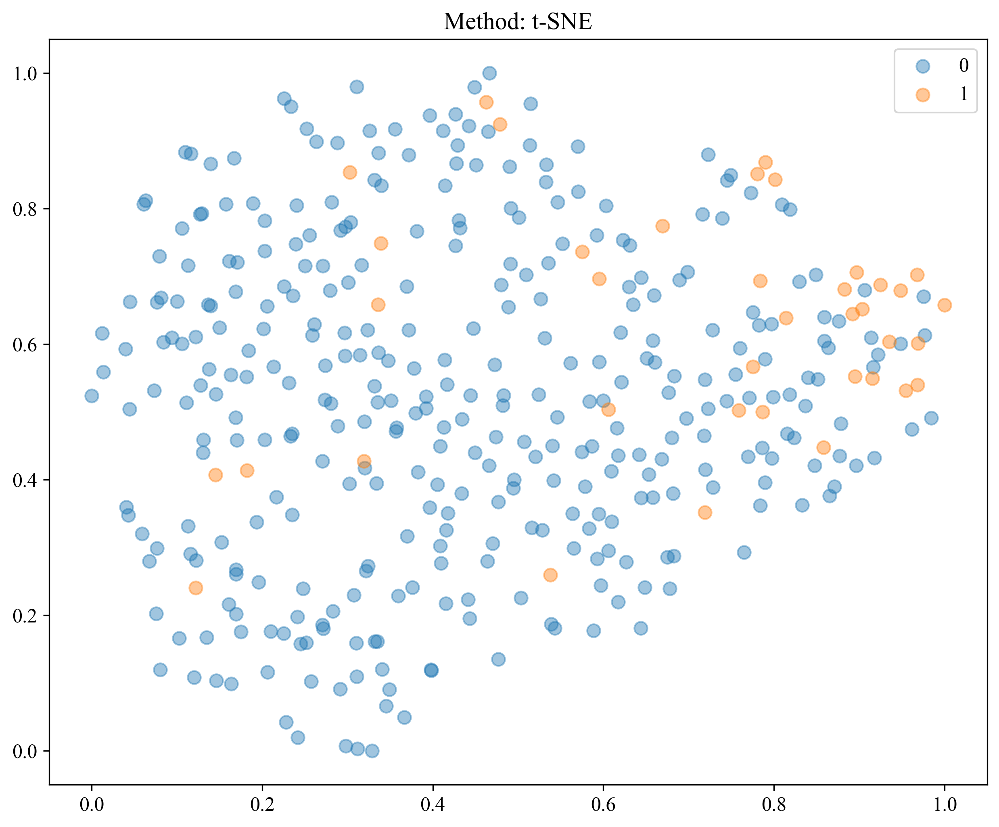

In [22]:
from onekey_algo.custom.components.comp1 import analysis_features
analysis_features(data[sel_feature[:-2]], data[labels[0]], methods='t-SNE', prefix=task_type)

## 构建数据

根据多中心的数据，进行数据划分。

In [23]:
import numpy as np
import onekey_algo.custom.components as okcomp

n_classes = 2
train_data = sel_data[(sel_data[group_info] == 'train')]
train_ids = ids[train_data.index]
train_data = train_data.reset_index()
train_data = train_data.drop('index', axis=1)
y_data = train_data[labels]
X_data = train_data.drop(labels + [group_info], axis=1)

test_data = sel_data[sel_data[group_info] != 'train']
test_ids = ids[test_data.index]
test_data = test_data.reset_index()
test_data = test_data.drop('index', axis=1)
y_test_data = test_data[labels]
X_test_data = test_data.drop(labels + [group_info], axis=1)

y_all_data = sel_data[labels]
X_all_data = sel_data.drop(labels + [group_info], axis=1)

column_names = X_data.columns
print(f"训练集样本数：{X_data.shape}, 验证集样本数：{X_test_data.shape}")

训练集样本数：(173, 129), 验证集样本数：(213, 129)


### Lasso

初始化Lasso模型，alpha为惩罚系数。具体的参数文档可以参考：[文档](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html?highlight=lasso#sklearn.linear_model.Lasso)

### 交叉验证

不同Lambda下的，特征的的权重大小。
```python
def lasso_cv_coefs(X_data, y_data, points=50, column_names: List[str] = None, **kwargs):
    """

    Args:
        X_data: 训练数据
        y_data: 监督数据
        points: 打印多少个点。默认50
        column_names: 列名，默认为None，当选择的数据很多的时候，建议不要添加此参数
        **kwargs: 其他用于打印控制的参数。

    """
 ```

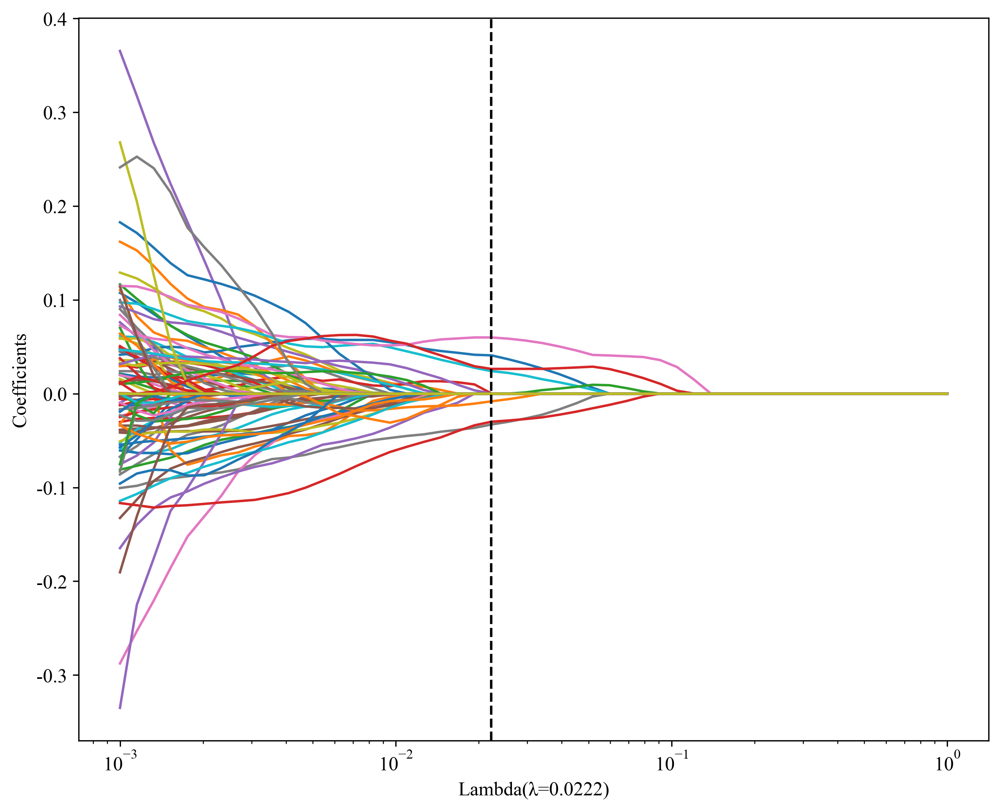

In [24]:
alpha = okcomp.comp1.lasso_cv_coefs(X_data, y_data, column_names=None)
plt.savefig(f'img/{task_type}_feature_lasso.svg', bbox_inches = 'tight')

### 模型效能

```python
def lasso_cv_efficiency(X_data, y_data, points=50, **kwargs):
    """

    Args:
        Xdata: 训练数据
        ydata: 测试数据
        points: 打印的数据密度
        **kwargs: 其他的图像样式
            # 数据点标记, fmt="o"
            # 数据点大小, ms=3
            # 数据点颜色, mfc="r"
            # 数据点边缘颜色, mec="r"
            # 误差棒颜色, ecolor="b"
            # 误差棒线宽, elinewidth=2
            # 误差棒边界线长度, capsize=2
            # 误差棒边界厚度, capthick=1
    Returns:
    """
 ```

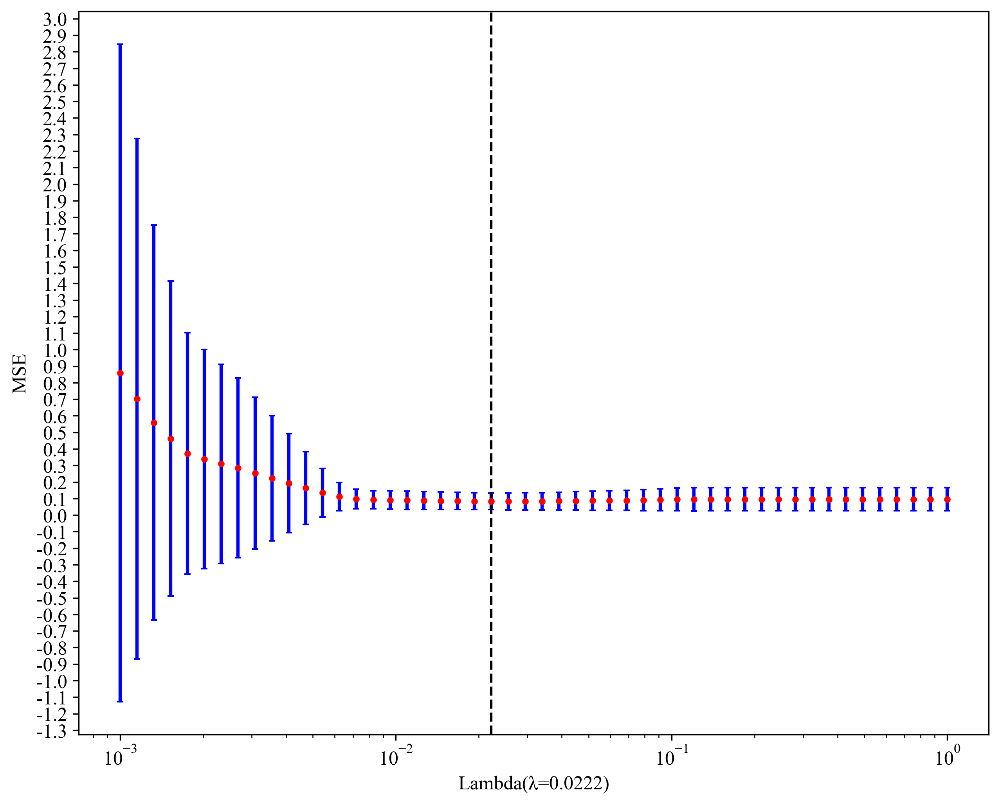

In [25]:
okcomp.comp1.lasso_cv_efficiency(X_data, y_data, points=50)
plt.savefig(f'img/{task_type}_feature_mse.svg', bbox_inches = 'tight')

### 惩罚系数

使用交叉验证的惩罚系数作为模型训练的基础。

In [26]:
from sklearn import linear_model

models = []
for label in labels:
    clf = linear_model.Lasso(alpha=alpha)
    clf.fit(X_data, y_data[label])
    models.append(clf)

### 特征筛选

筛选出其中coef > 0的特征。并且打印出相应的公式。

In [27]:
COEF_THRESHOLD = 1e-6 # 筛选的特征阈值
scores = []
selected_features = []
for label, model in zip(labels, models):
    feat_coef = [(feat_name, coef) for feat_name, coef in zip(column_names, model.coef_) 
                 if COEF_THRESHOLD is None or abs(coef) > COEF_THRESHOLD]
    selected_features.append([feat for feat, _ in feat_coef])
    formula = ' '.join([f"{coef:+.6f} * {feat_name}" for feat_name, coef in feat_coef])
    score = f"{label} = {model.intercept_} {'+' if formula[0] != '-' else ''} {formula}"
    scores.append(score)
    
print(scores[0])

label = 0.10404624277456646 + +0.000181 * intra_log_sigma_2_0_mm_3D_glcm_DifferenceAverage -0.032963 * intra_squareroot_firstorder_10Percentile +0.040772 * intra_squareroot_firstorder_RobustMeanAbsoluteDeviation +0.023923 * intra_wavelet_LHH_firstorder_Kurtosis -0.008240 * intra_wavelet_LHH_glcm_DifferenceVariance -0.029970 * intra_wavelet_LHL_glszm_SmallAreaEmphasis +0.059954 * intra_wavelet_LLL_firstorder_TotalEnergy +0.026253 * intra_wavelet_LLL_glszm_SizeZoneNonUniformity


### 特征权重

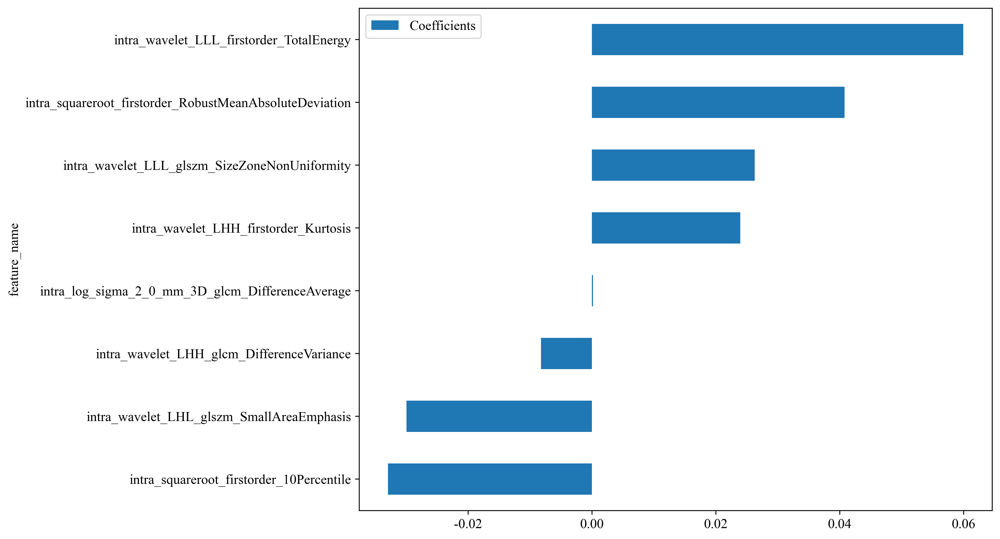

In [28]:
feat_coef = sorted(feat_coef, key=lambda x: x[1])
feat_coef_df = pd.DataFrame(feat_coef, columns=['feature_name', 'Coefficients'])
feat_coef_df.plot(x='feature_name', y='Coefficients', kind='barh')

plt.savefig(f'img/{task_type}_feature_weights.svg', bbox_inches = 'tight')

### 进一步筛选特征

使用Lasso筛选出来的Coefficients比较高的特征作为训练数据。

In [29]:
X_data = X_data[selected_features[0]]
X_test_data = X_test_data[selected_features[0]]
X_data.columns

Index(['intra_log_sigma_2_0_mm_3D_glcm_DifferenceAverage',
       'intra_squareroot_firstorder_10Percentile',
       'intra_squareroot_firstorder_RobustMeanAbsoluteDeviation',
       'intra_wavelet_LHH_firstorder_Kurtosis',
       'intra_wavelet_LHH_glcm_DifferenceVariance',
       'intra_wavelet_LHL_glszm_SmallAreaEmphasis',
       'intra_wavelet_LLL_firstorder_TotalEnergy',
       'intra_wavelet_LLL_glszm_SizeZoneNonUniformity'],
      dtype='object')

In [30]:
X_data.to_csv("X_data_intra.csv", index=False, encoding="utf-8-sig")

## 模型筛选

根据筛选出来的数据，做模型的初步选择。当前主要使用到的是Onekey中的

1. SVM，支持向量机，引用参考。
2. KNN，K紧邻，引用参考。
3. Decision Tree，决策树，引用参考。
4. Random Forests, 随机森林，引用参考。
5. XGBoost, bosting方法。引用参考。
6. LightGBM, bosting方法，引用参考。

In [31]:
model_names = get_param_in_cwd('ml_models') or ['SVM', 'KNN', 'RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM', 'MLP', 'LR']
models = okcomp.comp1.create_clf_model_none_overfit(model_names)
model_names = list(models.keys())

### 交叉验证

`n_trails`指定随机次数，每次采用的是80%训练，随机20%进行测试，找到最好的模型，以及对应的最好的数据划分。


```python
def get_bst_split(X_data: pd.DataFrame, y_data: pd.DataFrame,
            models: dict, test_size=0.2, metric_fn=accuracy_score, n_trails=10,
            cv: bool = False, shuffle: bool = False, metric_cut_off: float = None, random_state=None):
    """
    寻找数据集中最好的数据划分。
    Args:
        X_data: 训练数据
        y_data: 监督数据
        models: 模型名称，Dict类型、
        test_size: 测试集比例，只有当cv=False时生效
        metric_fn: 评价模型好坏的函数，默认准确率，可选roc_auc_score。
        n_trails: 尝试多少次寻找最佳数据集划分。
        cv: 是否是交叉验证，默认是False，当为True时，n_trails为交叉验证的n_fold
        shuffle: 是否进行随机打乱
        metric_cut_off: 当metric_fn的值达到多少时进行截断。
        random_state: 随机种子

    Returns: {'max_idx': max_idx, "max_model": max_model, "max_metric": max_metric, "results": results}

    """
```

**注意：这里采用了【挑数据】，如果想要严谨，请修改`n_trails=1`。**

[2026-06-28 23:54:45 - <frozen onekey_algo.custom.components.comp1>: 701]	WARNING	当cv=True的时候，采用的是交叉验证的模式，此时test_size的参数是不生效的，我们将忽略这个test_size设置。如果需要手动指定测试集比例，请修改cv=False。


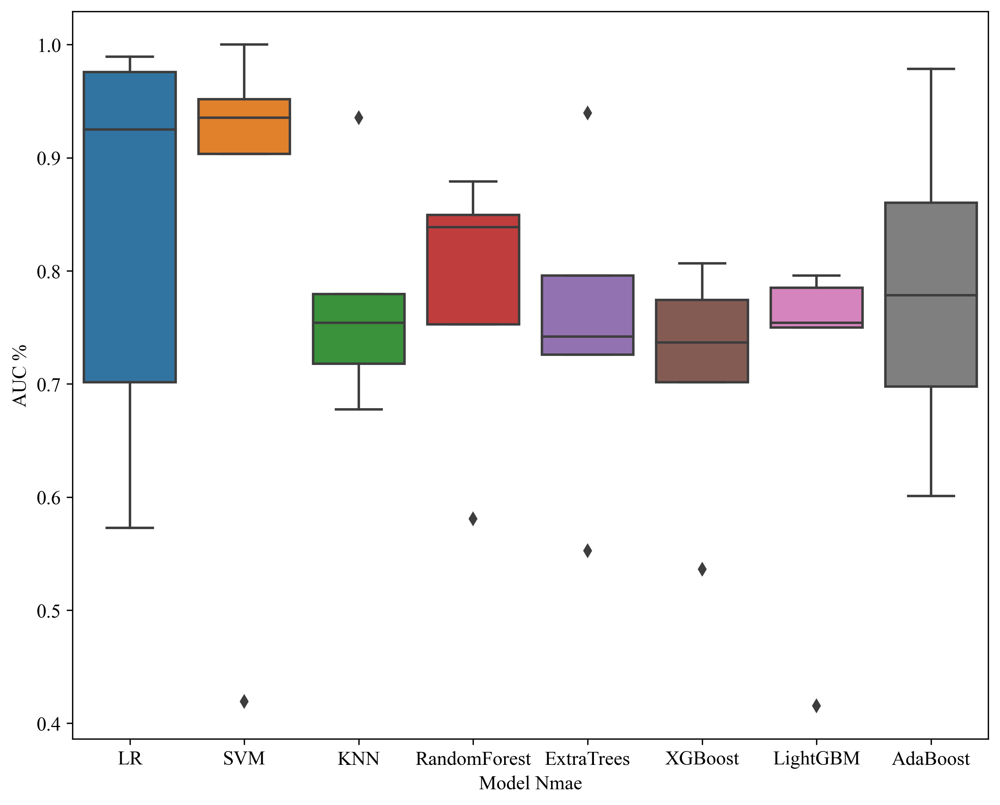

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score

# 随机使用n_trails次数据划分，找到最好的一次划分方法，并且保存在results中。
results = okcomp.comp1.get_bst_split(X_data, y_data, models, test_size=0.2, metric_fn=roc_auc_score, n_trails=5, cv=True, random_state=0)
_, (X_train_sel, X_test_sel, y_train_sel, y_test_sel) = results['results'][results['max_idx']]
X_train_sel, X_test_sel, y_train_sel, y_test_sel = X_data, X_test_data, y_data, y_test_data
trails, _ = zip(*results['results'])
cv_results = pd.DataFrame(trails, columns=model_names)
# 可视化每个模型在不同的数据划分中的效果。
sns.boxplot(data=cv_results)
plt.ylabel('AUC %')
plt.xlabel('Model Nmae')
plt.savefig(f'img/{task_type}_model_cv.svg', bbox_inches = 'tight')

## 模型筛选

使用最好的数据划分，进行后续的模型研究。

**注意**: 一般情况下论文使用的是随机划分的数据，但也有些论文使用【刻意】筛选的数据划分。

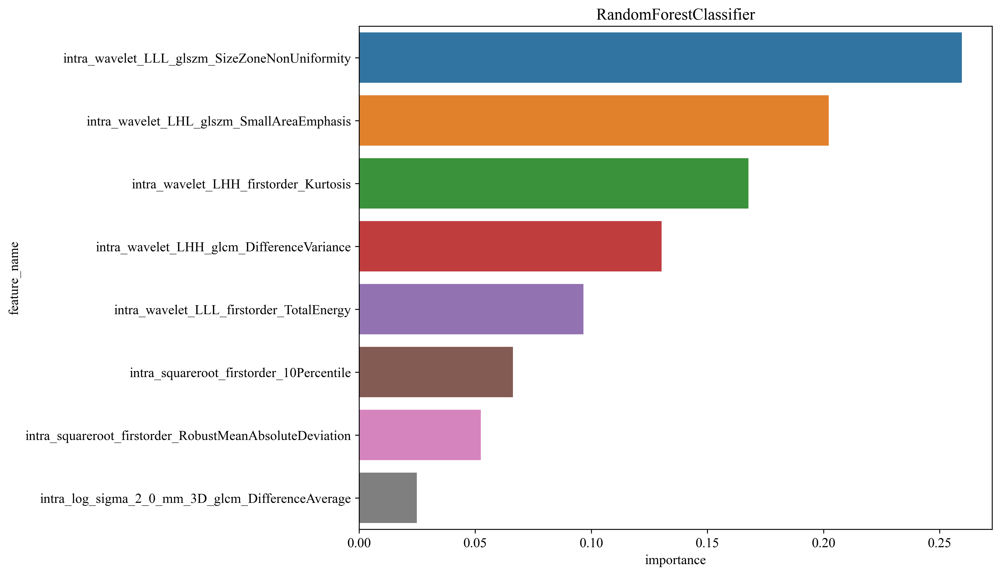

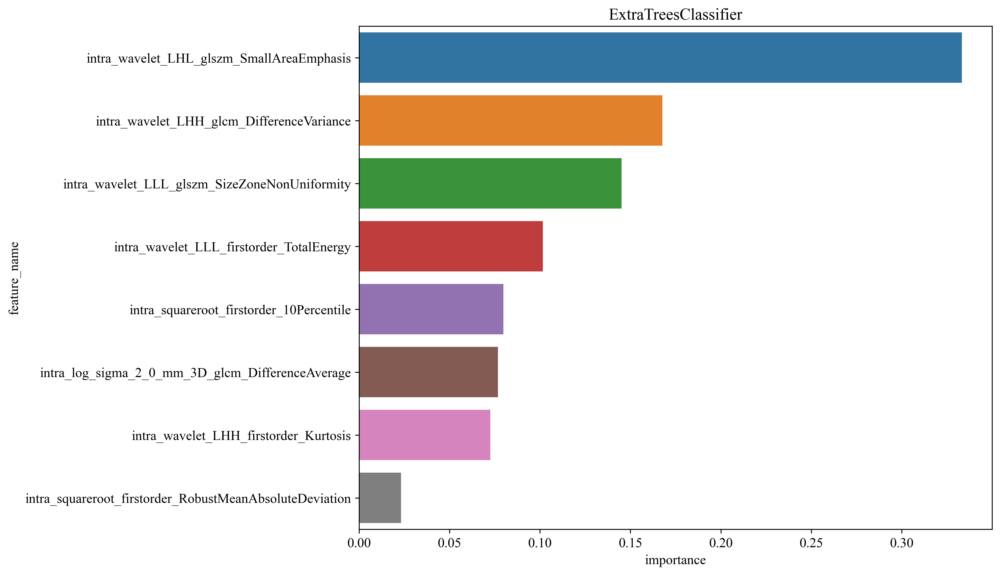

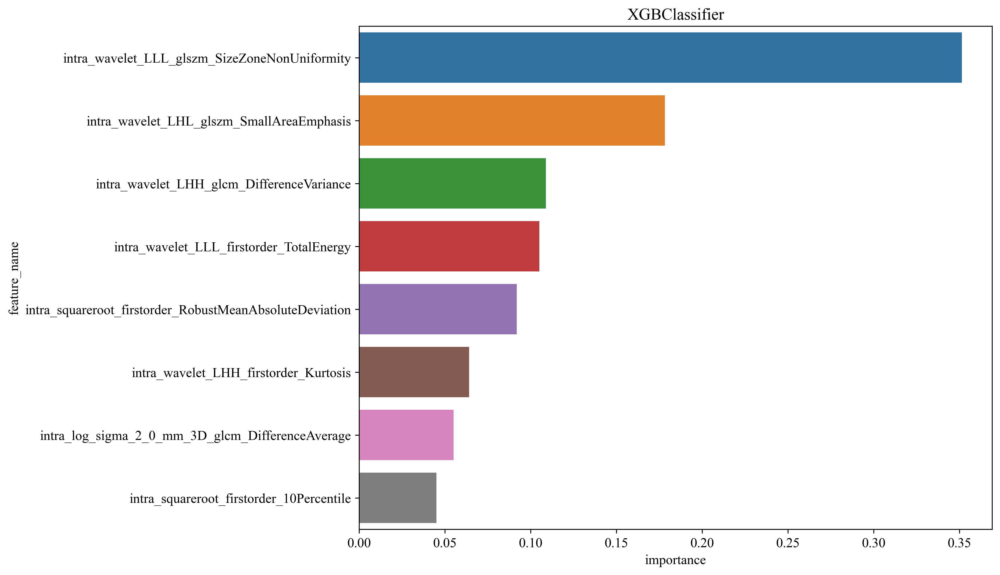

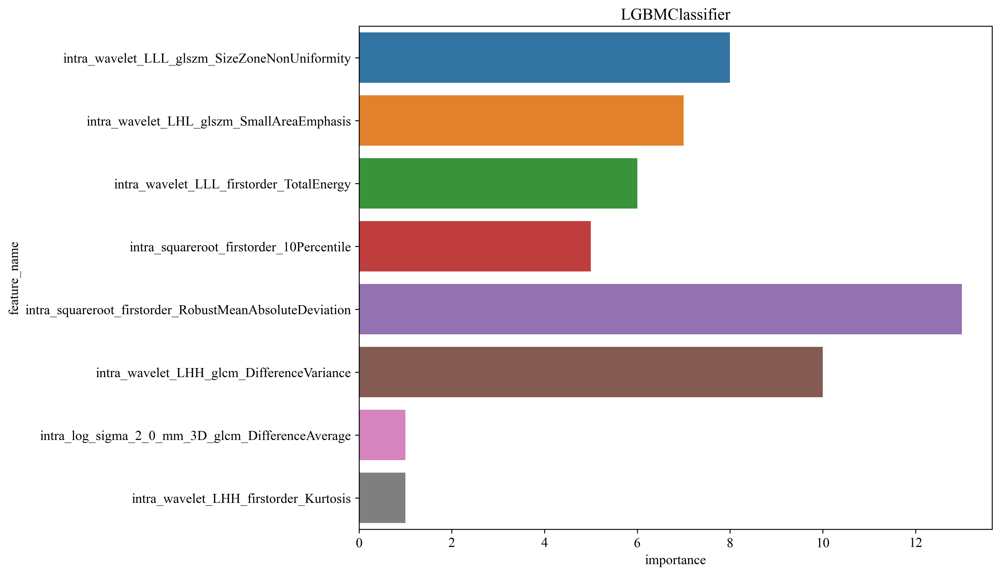

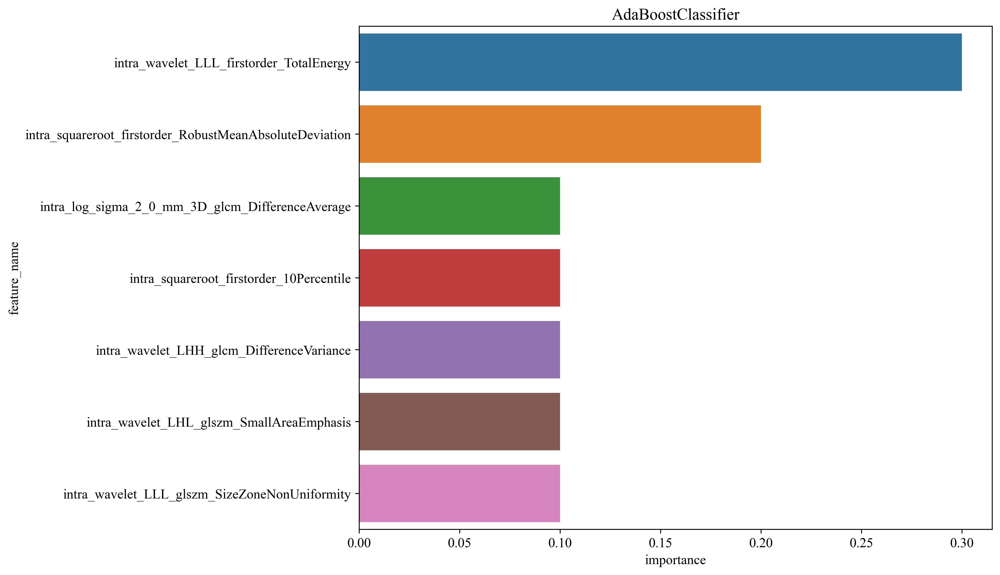

In [33]:
import joblib
from onekey_algo.custom.components.comp1 import plot_feature_importance, plot_learning_curve, smote_resample
targets = []
os.makedirs('models', exist_ok=True)
for l in labels:
    new_models = list(okcomp.comp1.create_clf_model_none_overfit(model_names).values())
    for mn, m in zip(model_names, new_models):
        X_train_smote, y_train_smote = X_train_sel, y_train_sel
        # 取消下一行的注释可以使用Smote进行采样，解决样本不均衡的问题。
        X_train_smote, y_train_smote = smote_resample(X_train_sel, y_train_sel)
        m.fit(X_train_smote, y_train_smote[l])
        # 保存训练的模型
        joblib.dump(m, f'models/{task_type}_{mn}_{l}.pkl') 
        # 输出模型特征重要性，只针对高级树模型有用
        plot_feature_importance(m, selected_features[0], save_dir='img')
        
#         plot_learning_curve(m, X_train_sel, y_train_sel, title=f'Learning Curve {mn}')
#         plt.savefig(f"img/{task_type}_{mn}_learning_curve.svg", bbox_inches='tight')
        plt.show()
    targets.append(new_models)

## 预测结果

* predictions，二维数据，每个label对应的每个模型的预测结果。
* pred_scores，二维数据，每个label对应的每个模型的预测概率值。

In [34]:
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from onekey_algo.custom.components.delong import calc_95_CI
from onekey_algo.custom.components.metrics import analysis_pred_binary

predictions = [[(model.predict(X_train_sel), model.predict(X_test_sel)) 
                for model in target] for label, target in zip(labels, targets)]
pred_scores = [[(model.predict_proba(X_train_sel), model.predict_proba(X_test_sel)) 
                for model in target] for label, target in zip(labels, targets)]

metric = []
pred_sel_idx = []
for label, prediction, scores in zip(labels, predictions, pred_scores):
    pred_sel_idx_label = []
    for mname, (train_pred, test_pred), (train_score, test_score) in zip(model_names, prediction, scores):
        # 计算训练集指数
        acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres = analysis_pred_binary(y_train_sel[label], 
                                                                                              train_score[:, 1])
        ci = f"{ci[0]:.4f} - {ci[1]:.4f}"
        metric.append((mname, acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres, f"{label}-train"))
                 
        # 计算验证集指标
        acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres = analysis_pred_binary(y_test_sel[label], 
                                                                                              test_score[:, 1])
        ci = f"{ci[0]:.4f} - {ci[1]:.4f}"
        metric.append((mname, acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres, f"{label}-test"))
        # 计算thres对应的sel idx
        pred_sel_idx_label.append(np.logical_or(test_score[:, 0] >= thres, test_score[:, 1] >= thres))
    
    pred_sel_idx.append(pred_sel_idx_label)
metric = pd.DataFrame(metric, index=None, columns=['model_name', 'Accuracy', 'AUC', '95% CI',
                                                   'Sensitivity', 'Specificity', 
                                                   'PPV', 'NPV', 'Precision', 'Recall', 'F1',
                                                   'Threshold', 'Task'])
metric

,model_name,Accuracy,AUC,95% CI,Sensitivity,Specificity,PPV,NPV,Precision,Recall,F1,Threshold,Task
0,LR,0.867,0.887,0.7938 - 0.9804,0.833,0.871,0.429,0.978,0.429,0.833,0.566,0.578,label-train
1,LR,0.700,0.784,0.6759 - 0.8930,0.750,0.694,0.203,0.964,0.203,0.750,0.319,0.344,label-test
2,SVM,0.960,0.955,0.9090 - 1.0000,0.833,0.974,0.789,0.981,0.789,0.833,0.811,0.839,label-train
3,SVM,0.540,0.781,0.6785 - 0.8827,0.950,0.497,0.164,0.990,0.164,0.950,0.279,0.065,label-test
4,KNN,0.994,0.991,0.9732 - 1.0000,0.944,1.000,1.000,0.994,1.000,0.944,0.971,1.000,label-train
5,KNN,0.638,0.748,0.6354 - 0.8612,0.800,0.622,0.180,0.968,0.180,0.800,0.294,0.200,label-test
6,RandomForest,0.919,0.945,0.8987 - 0.9920,0.778,0.935,0.583,0.973,0.583,0.778,0.667,0.650,label-train
7,RandomForest,0.761,0.861,0.7938 - 0.9274,0.850,0.751,0.262,0.980,0.262,0.850,0.400,0.299,label-test
8,ExtraTrees,0.844,0.891,0.8117 - 0.9701,0.833,0.845,0.385,0.978,0.385,0.833,0.526,0.515,label-train
9,ExtraTrees,0.808,0.786,0.6791 - 0.8929,0.650,0.824,0.277,0.958,0.277,0.650,0.388,0.519,label-test


### 绘制曲线

绘制的不同模型的准确率柱状图和折线图曲线。

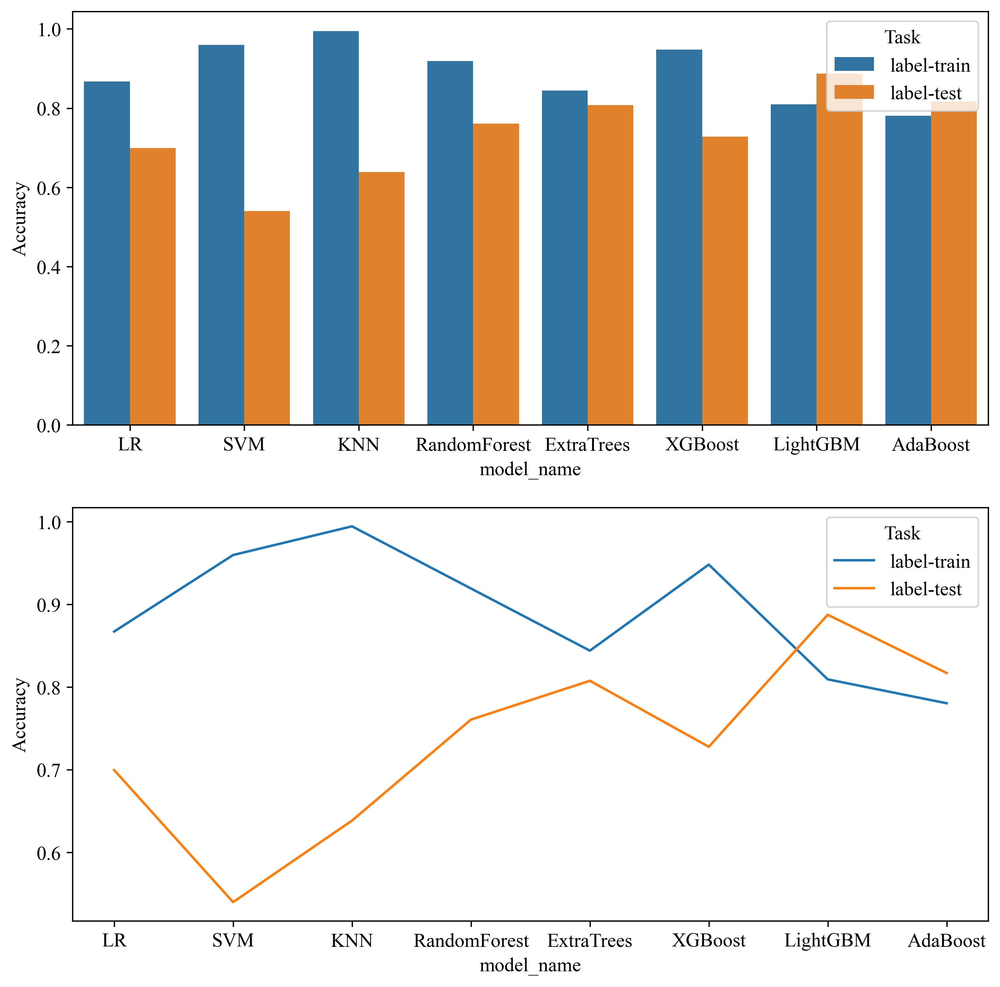

In [35]:
import seaborn as sns

plt.figure(figsize=(10, 10))
plt.subplot(211)
sns.barplot(x='model_name', y='Accuracy', data=metric, hue='Task')
plt.subplot(212)
sns.lineplot(x='model_name', y='Accuracy', data=metric, hue='Task')
plt.savefig(f'img/{task_type}_model_acc.svg', bbox_inches = 'tight')

### 绘制ROC曲线
确定最好的模型，并且绘制曲线。

```python
def draw_roc(y_test, y_score, title='ROC', labels=None):
```

`sel_model = ['SVM', 'KNN']`参数为想要绘制的模型对应的参数。

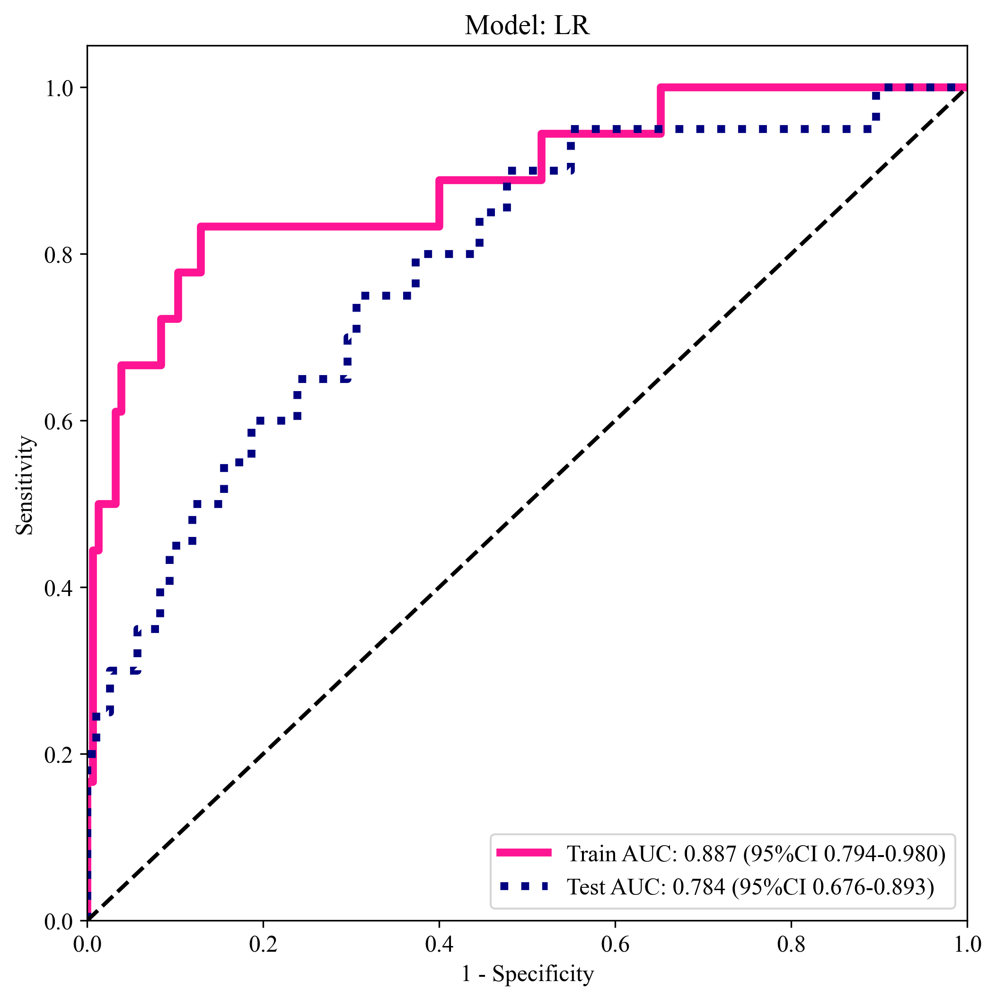

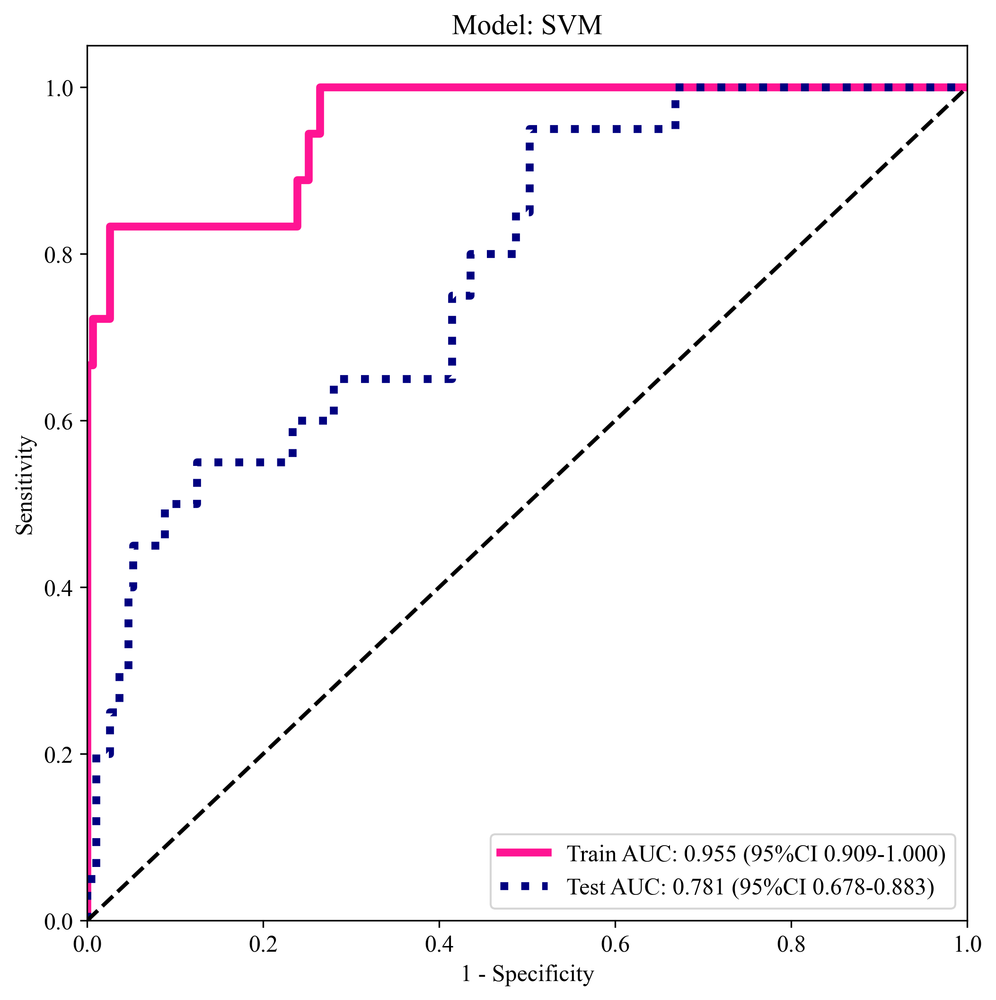

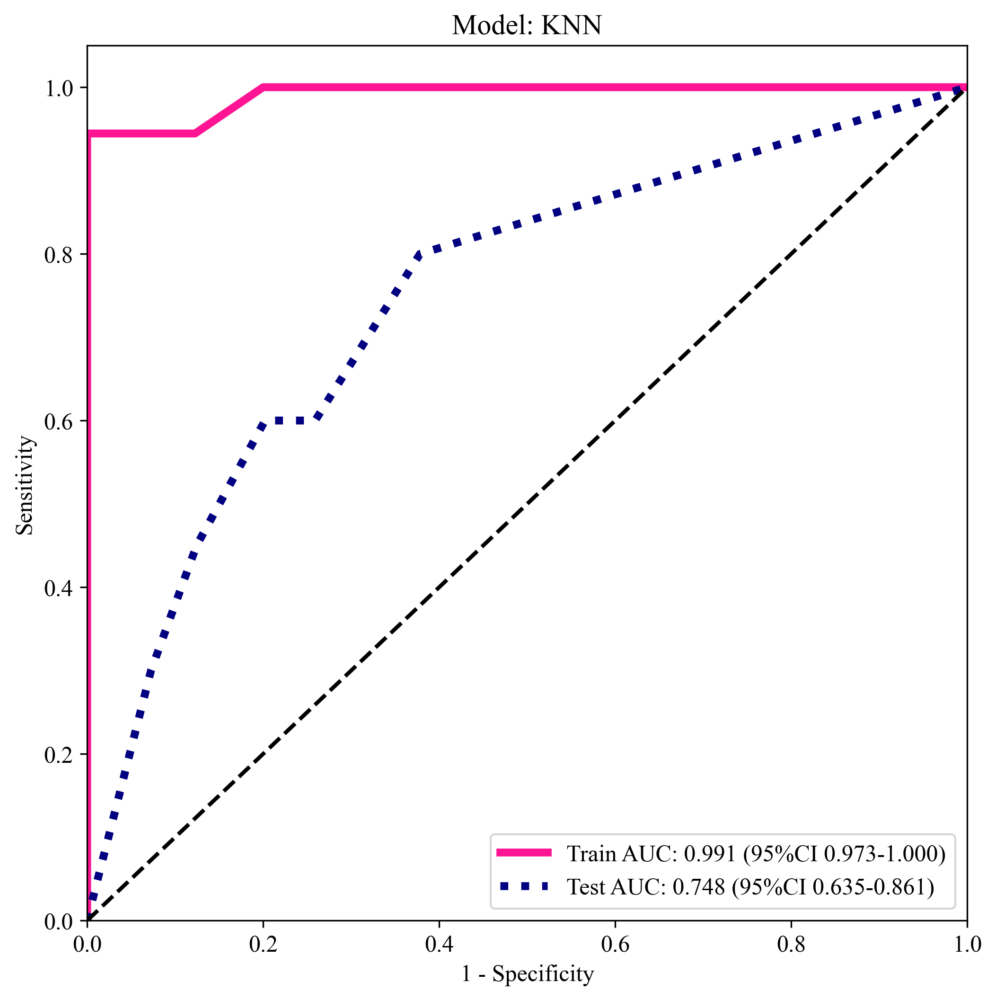

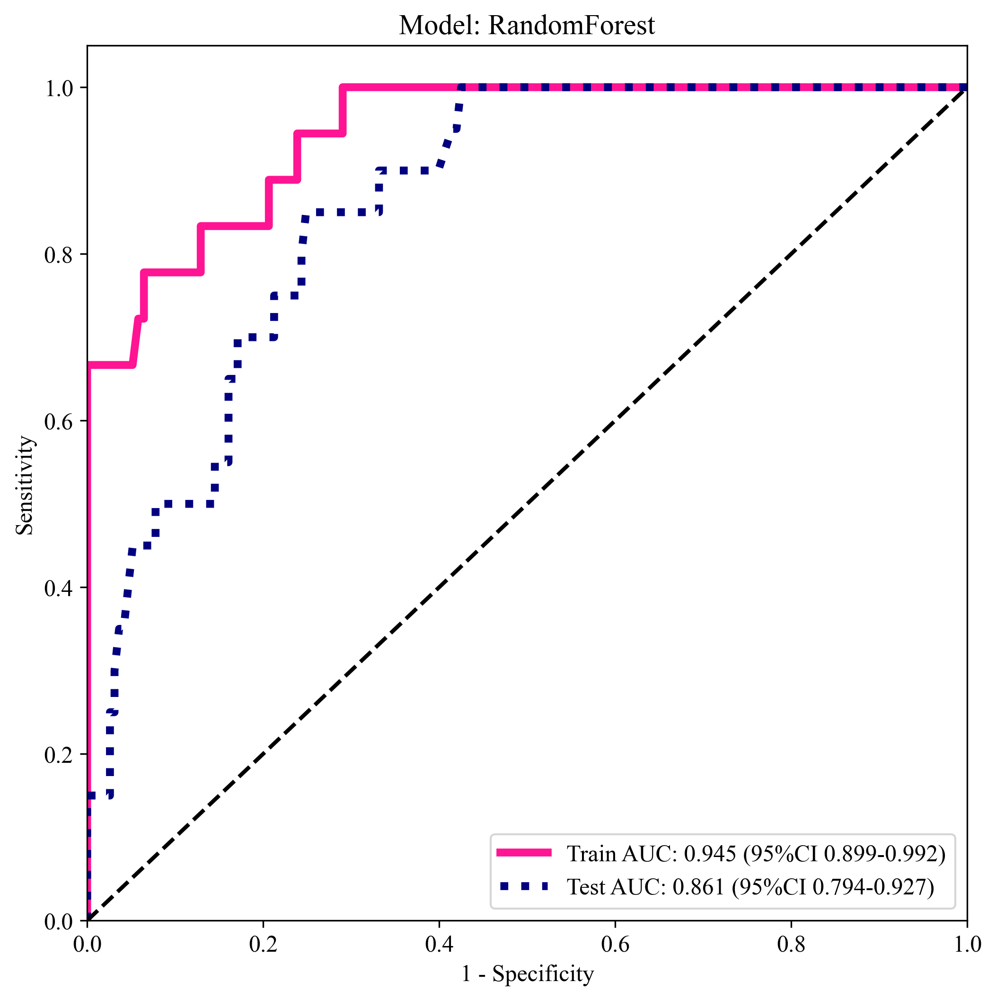

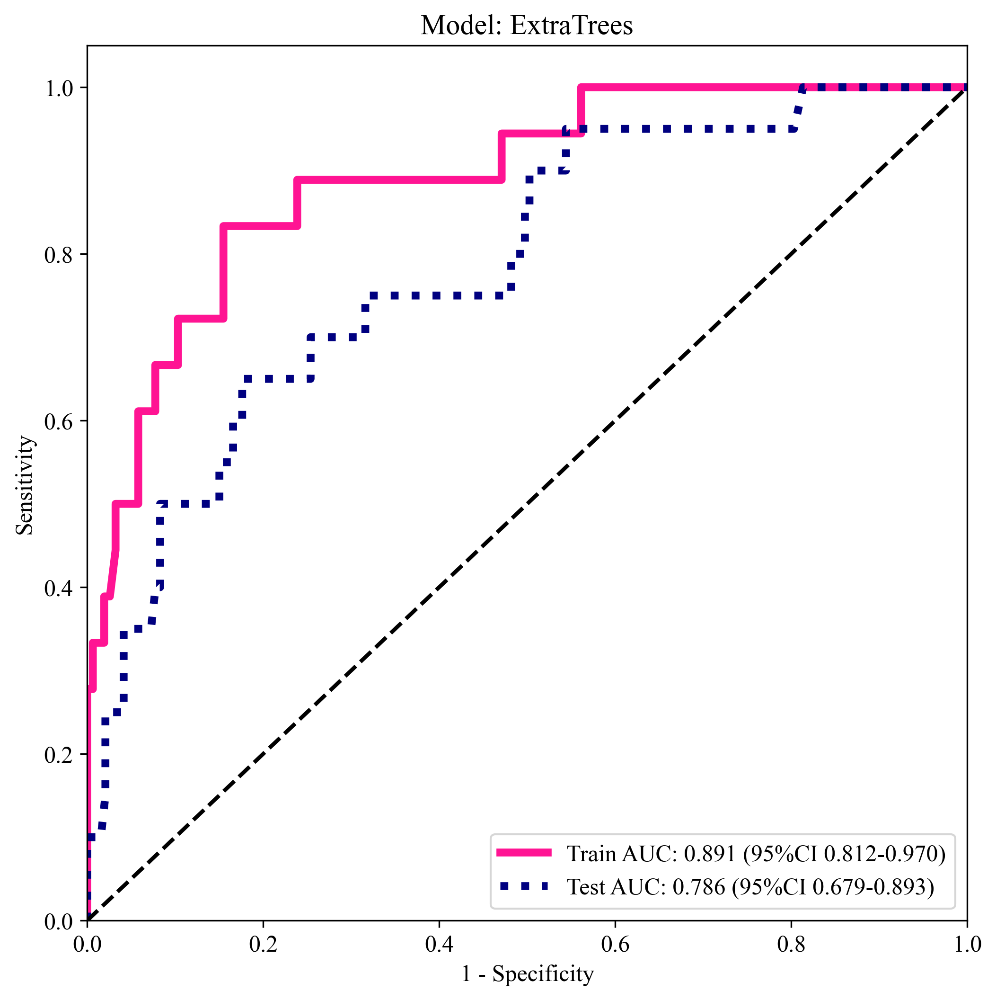

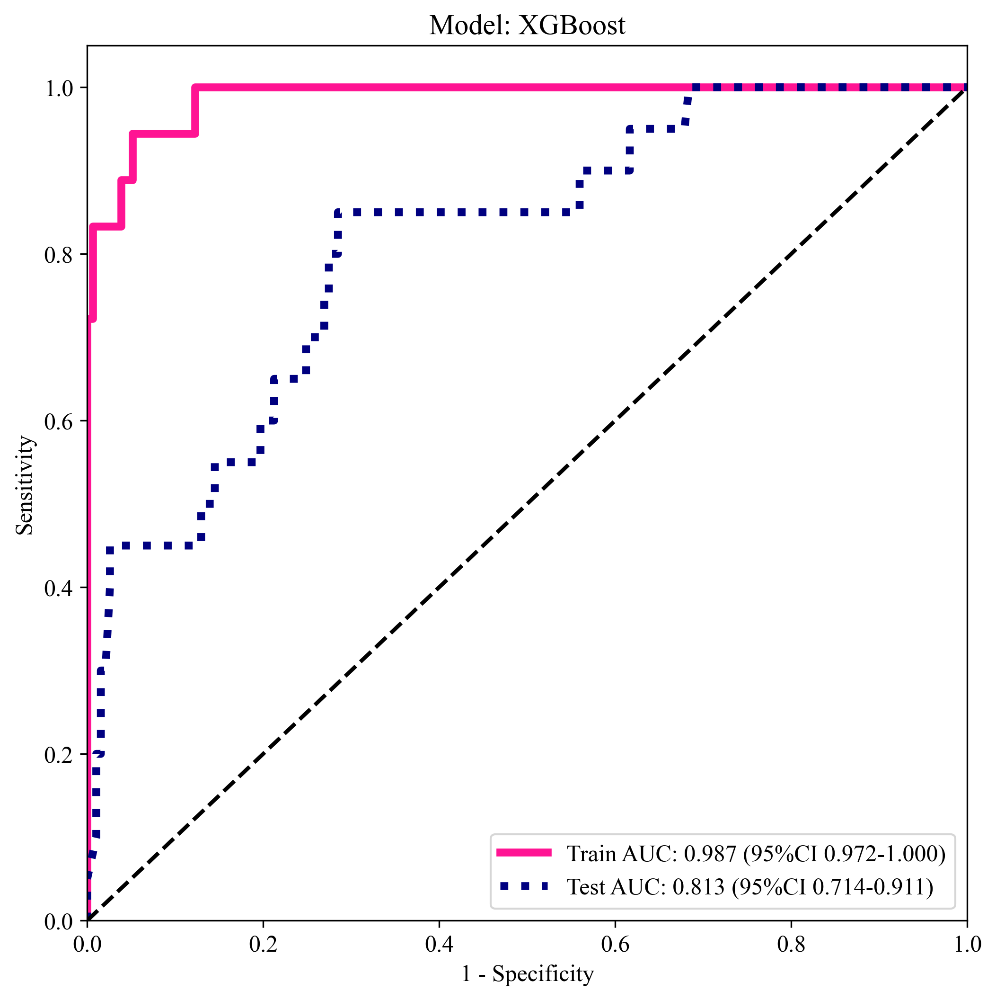

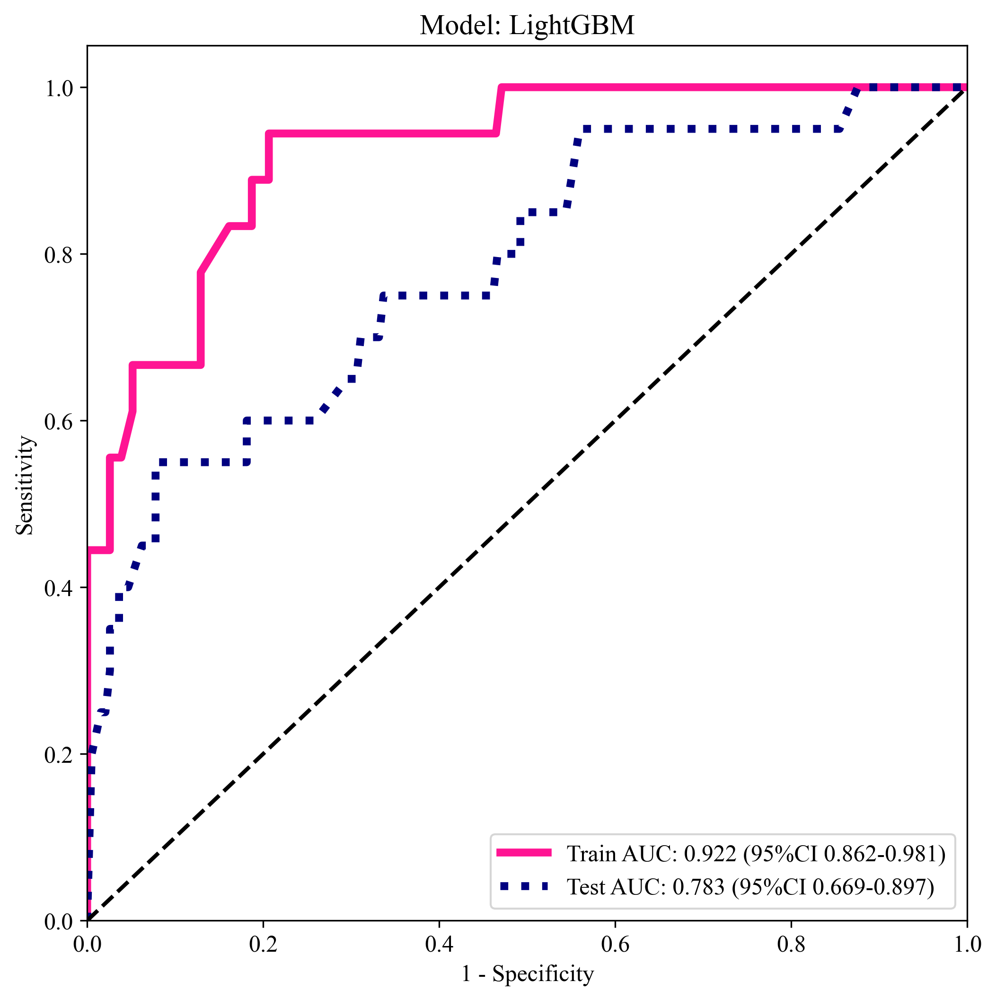

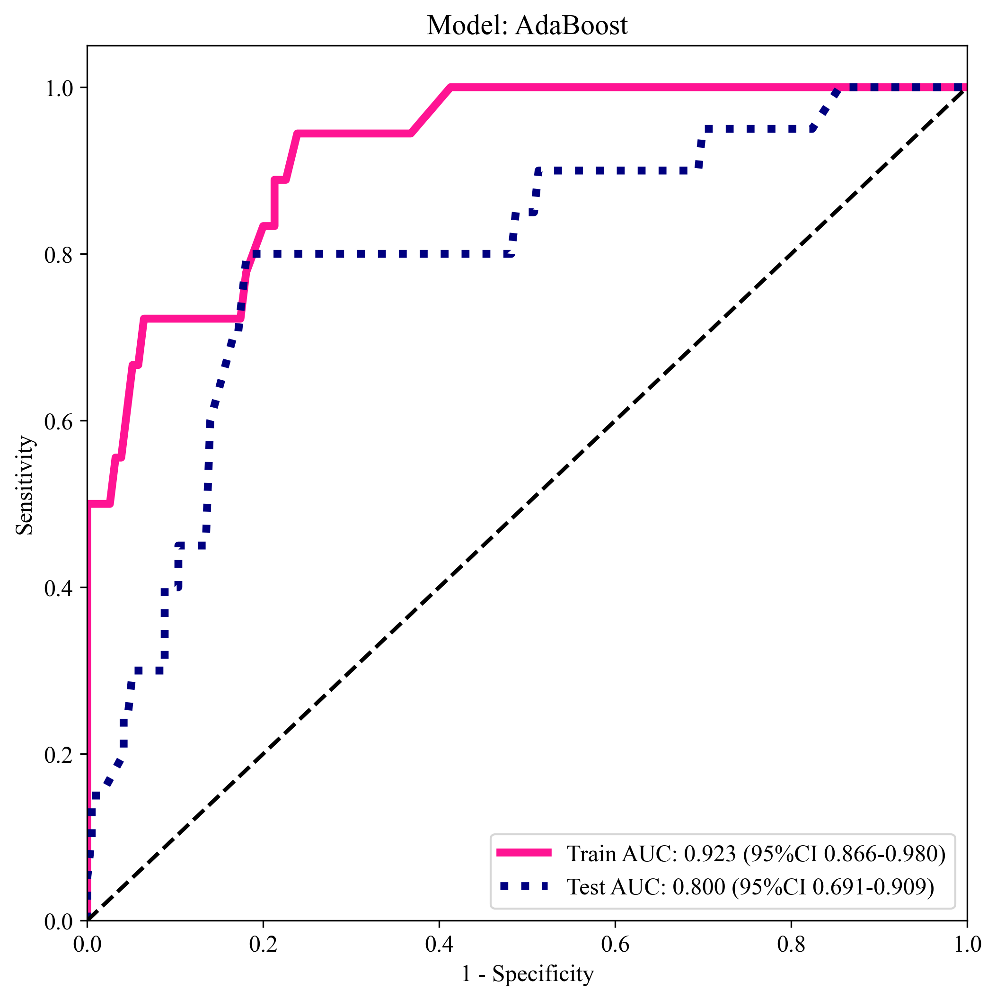

In [36]:
sel_model = model_names

for sm in sel_model:
    if sm in model_names:
        sel_model_idx = model_names.index(sm)
    
        # Plot all ROC curves
        plt.figure(figsize=(8, 8))
        for pred_score, label in zip(pred_scores, labels):
            okcomp.comp1.draw_roc([np.array(y_train_sel[label]), np.array(y_test_sel[label])], 
                                  pred_score[sel_model_idx], 
                                  labels=['Train', 'Test'], title=f"Model: {sm}")
            plt.savefig(f'img/{task_type}_model_{sm}_roc.svg', bbox_inches = 'tight')

#### 汇总所有模型

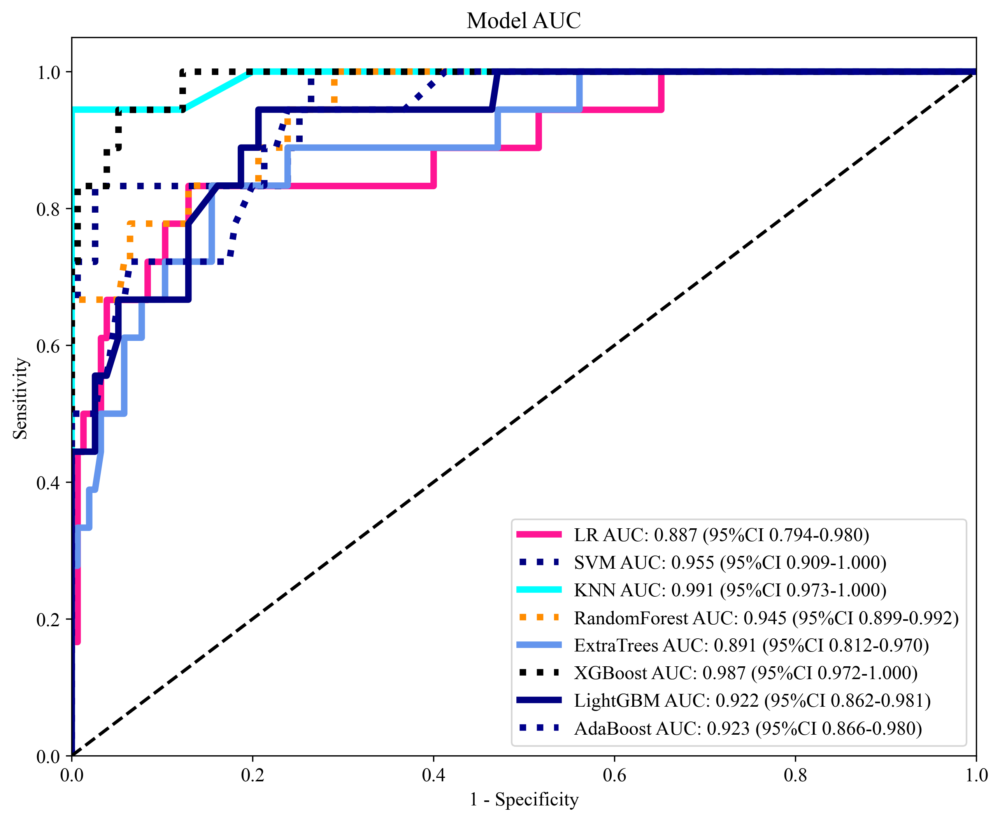

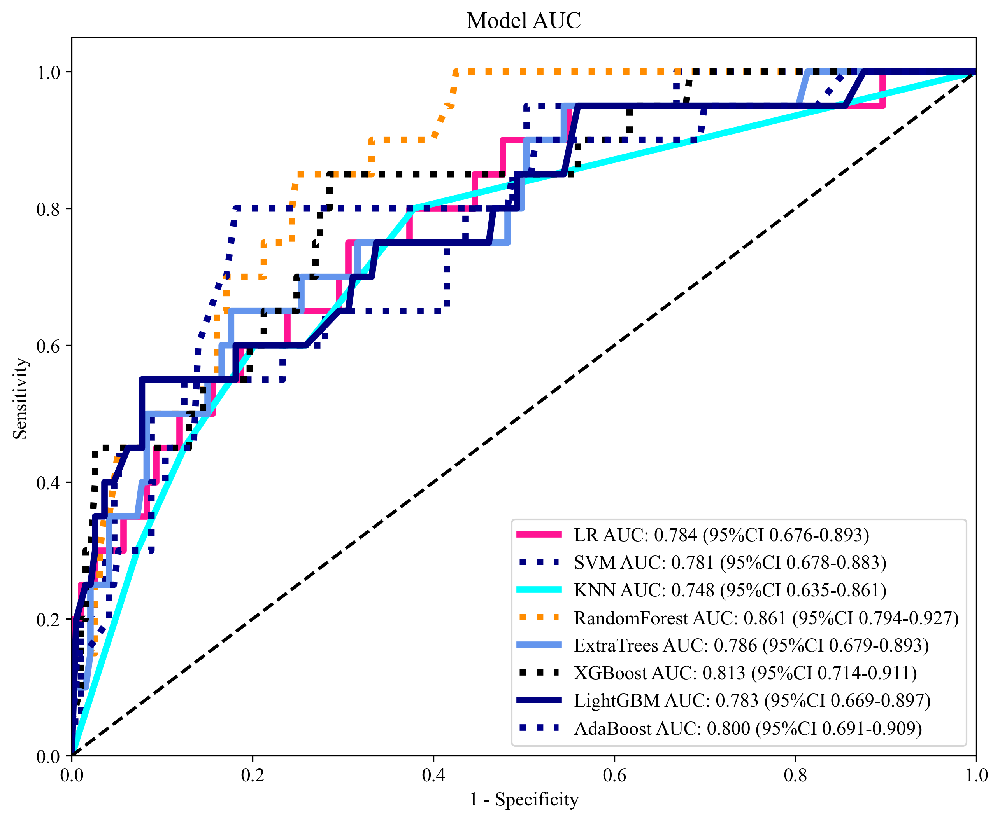

In [37]:
sel_model = model_names

for pred_score, label in zip(pred_scores, labels):
    pred_test_scores = []
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            pred_test_scores.append(pred_score[sel_model_idx][0])
    okcomp.comp1.draw_roc([np.array(y_train_sel[label])] * len(pred_test_scores), 
                          pred_test_scores, 
                          labels=sel_model, title=f"Model AUC")
    plt.savefig(f'img/{task_type}_model_roc_train.svg', bbox_inches = 'tight')
    plt.show()

for pred_score, label in zip(pred_scores, labels):
    pred_test_scores = []
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            pred_test_scores.append(pred_score[sel_model_idx][1])
    okcomp.comp1.draw_roc([np.array(y_test_sel[label])] * len(pred_test_scores), 
                          pred_test_scores, 
                          labels=sel_model, title=f"Model AUC")
    plt.savefig(f'img/{task_type}_model_roc_test.svg', bbox_inches = 'tight')

### DCA 决策曲线

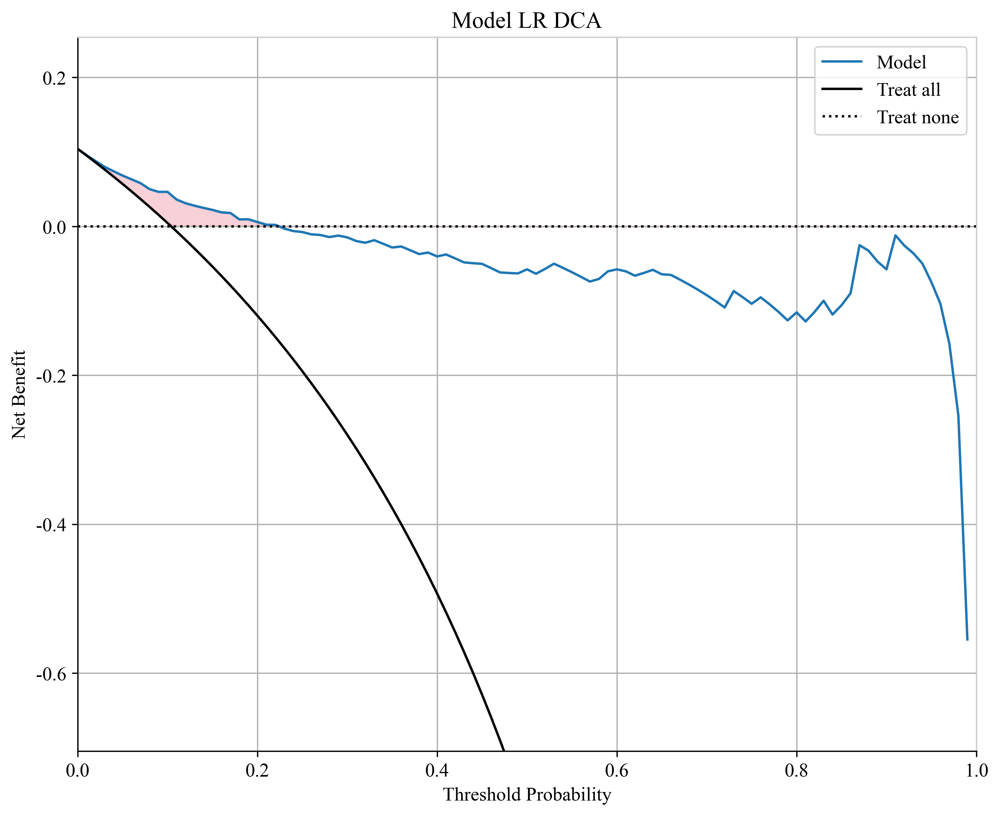

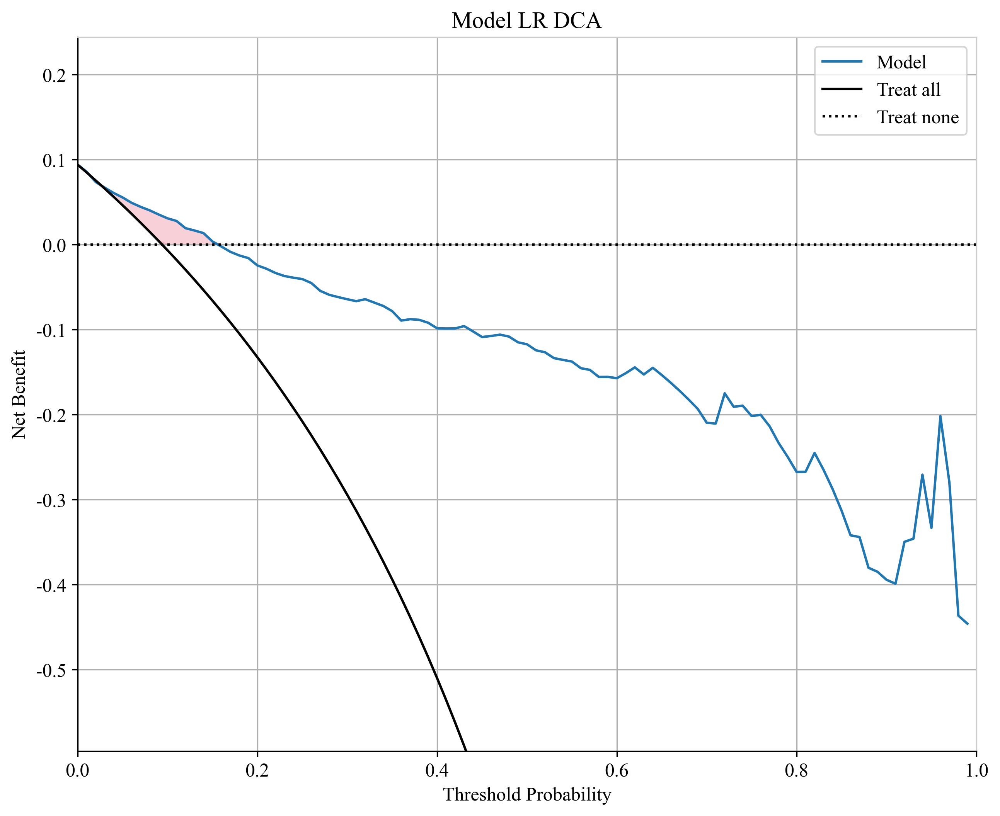

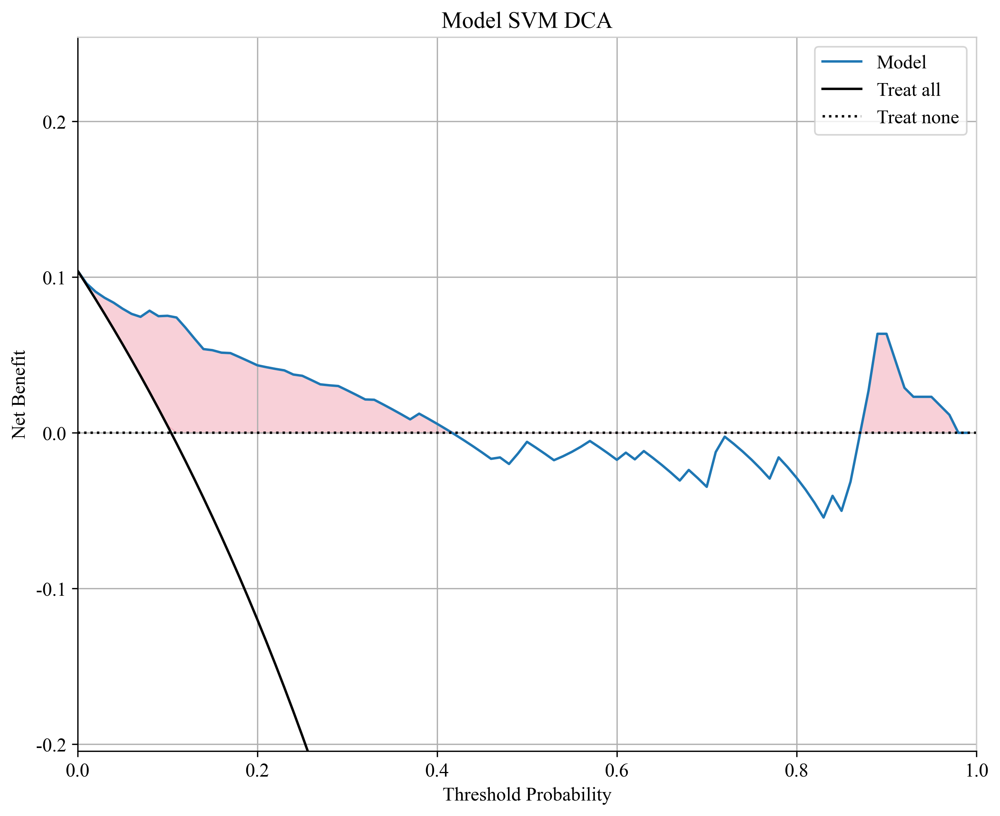

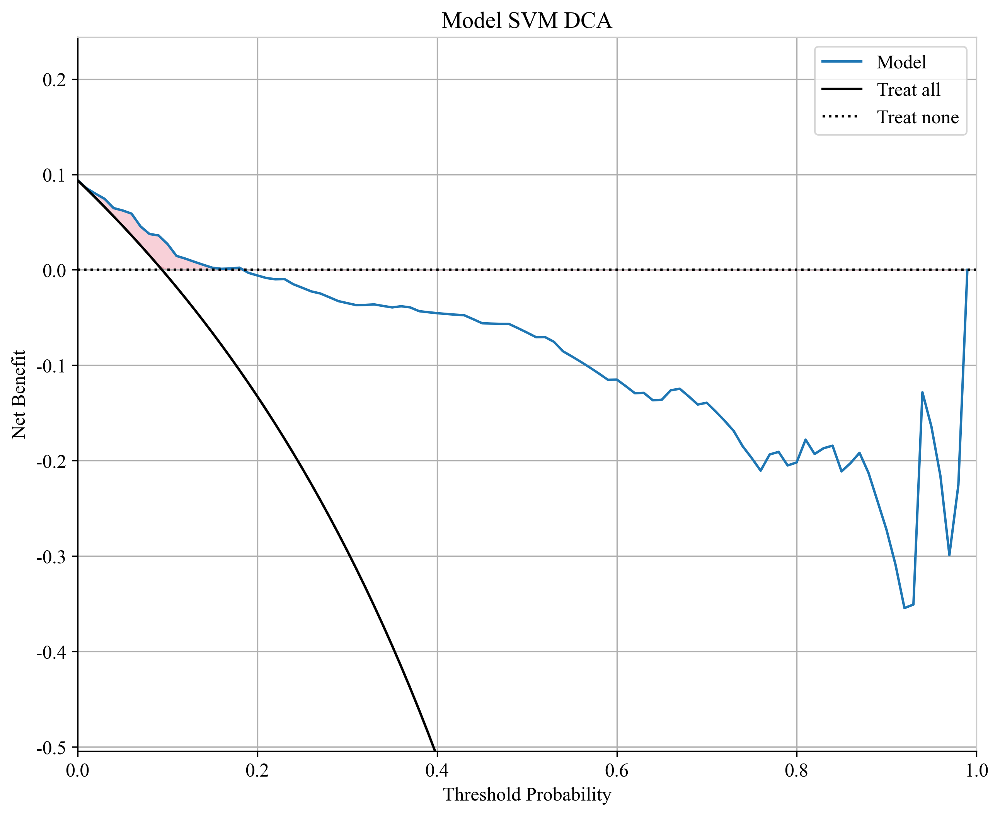

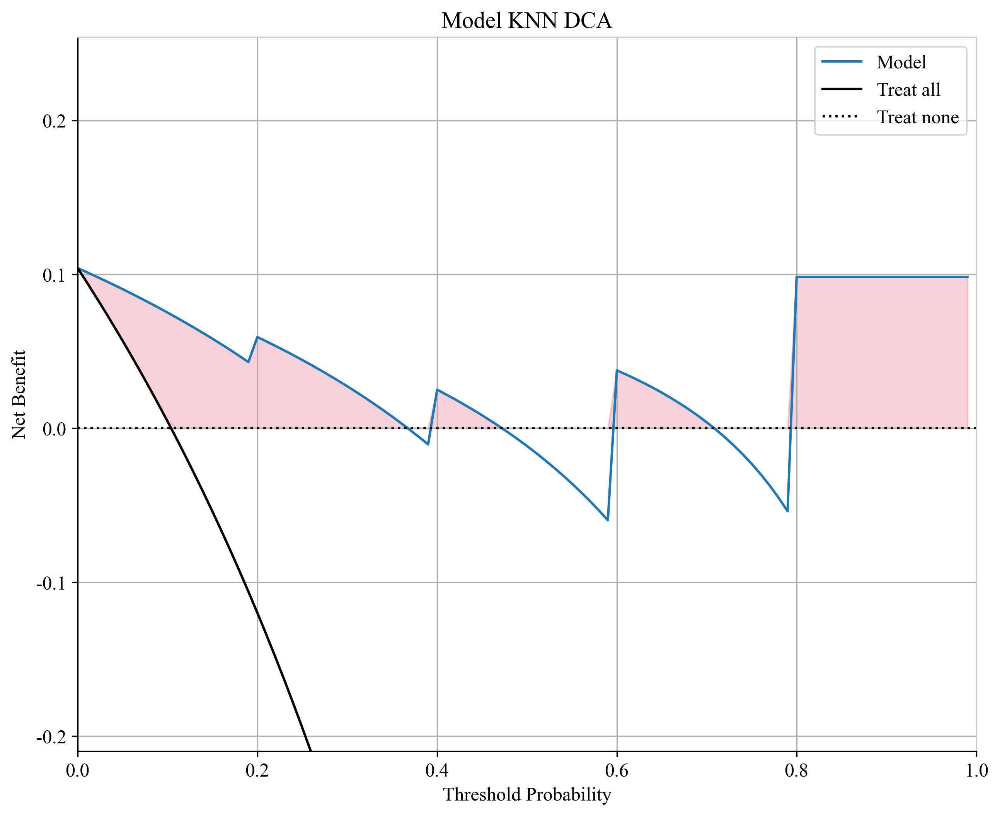

...

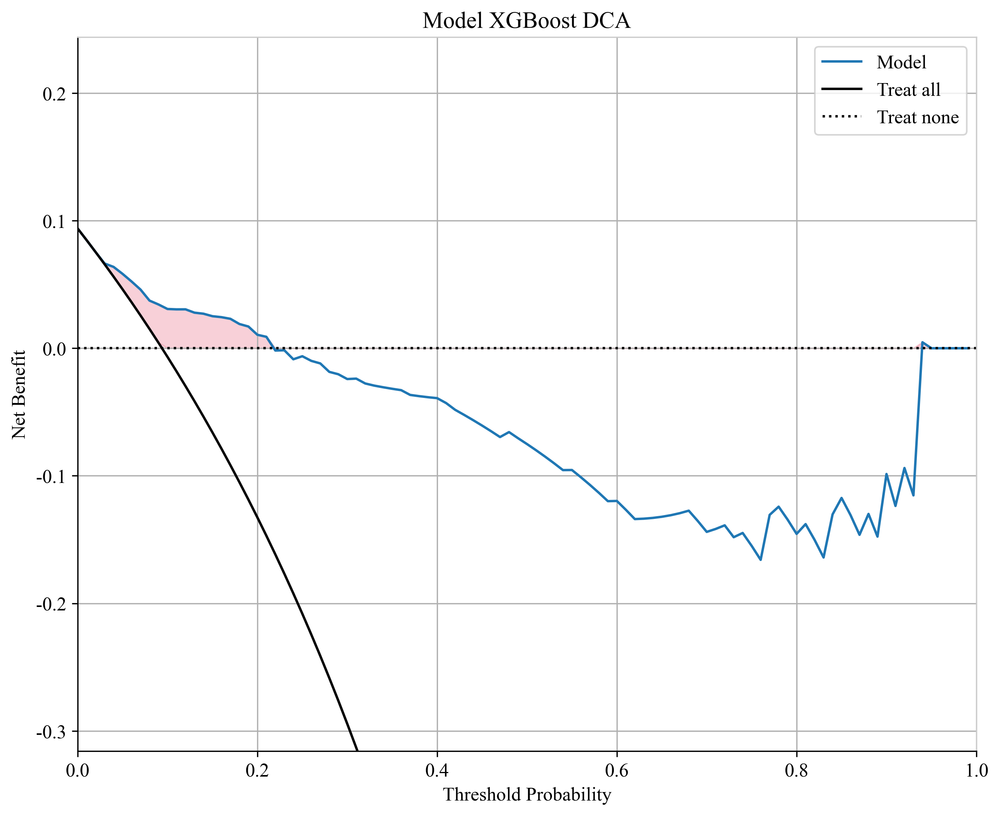

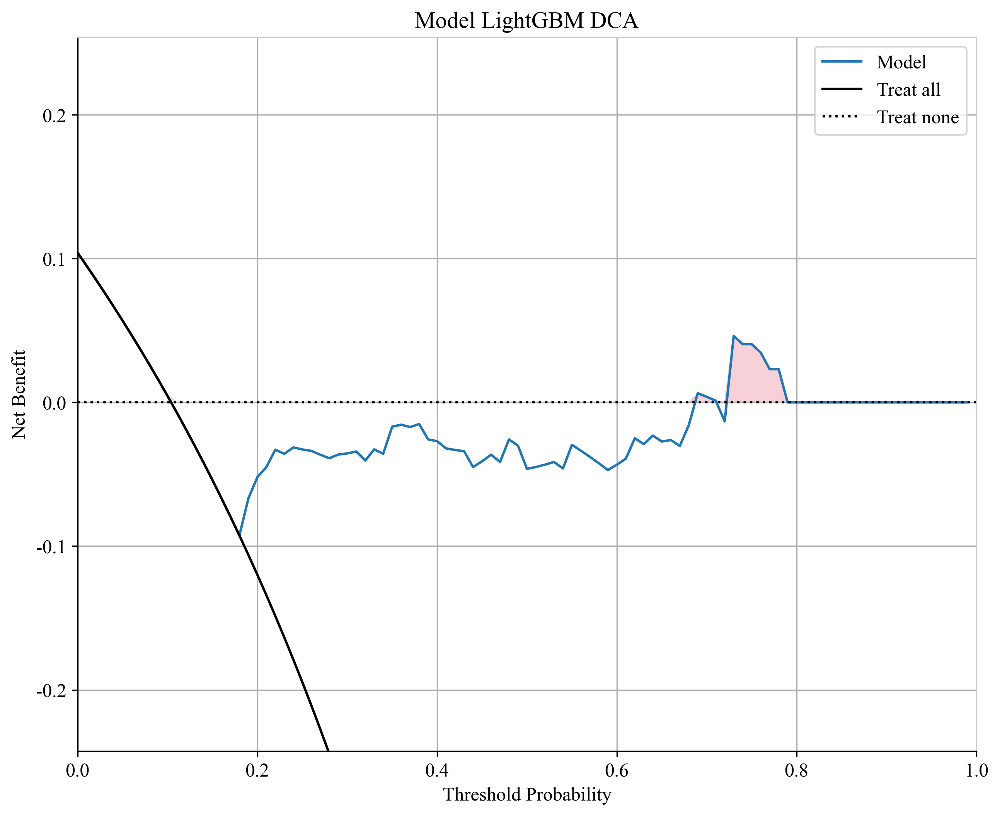

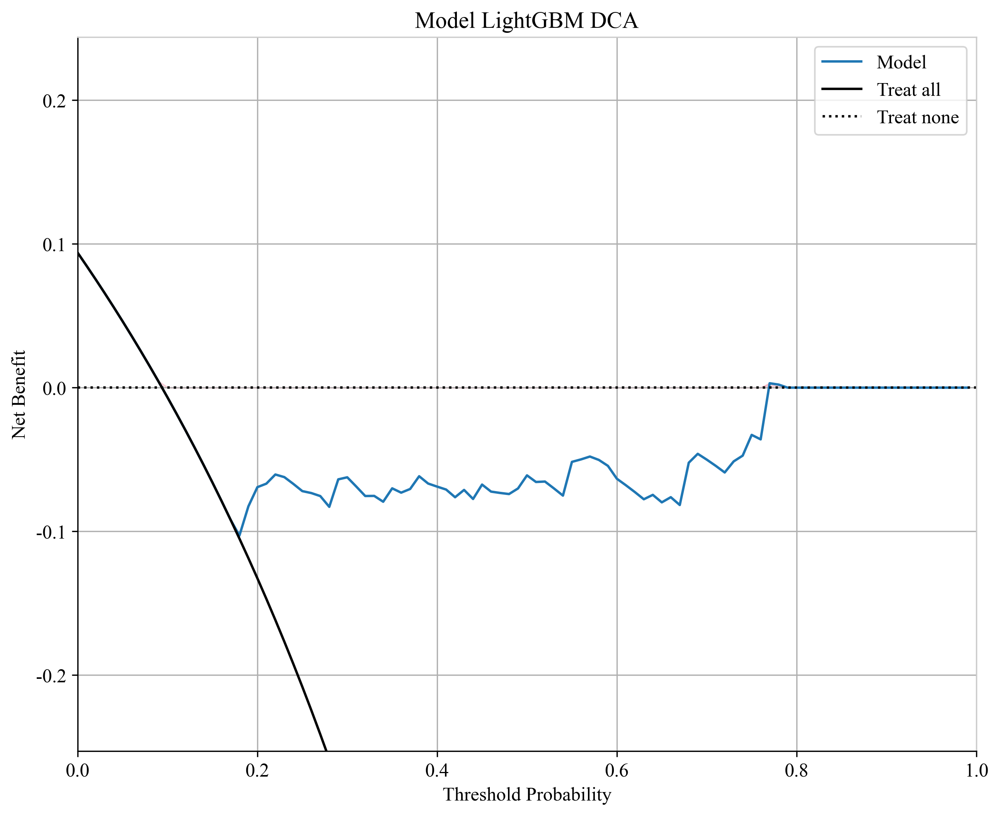

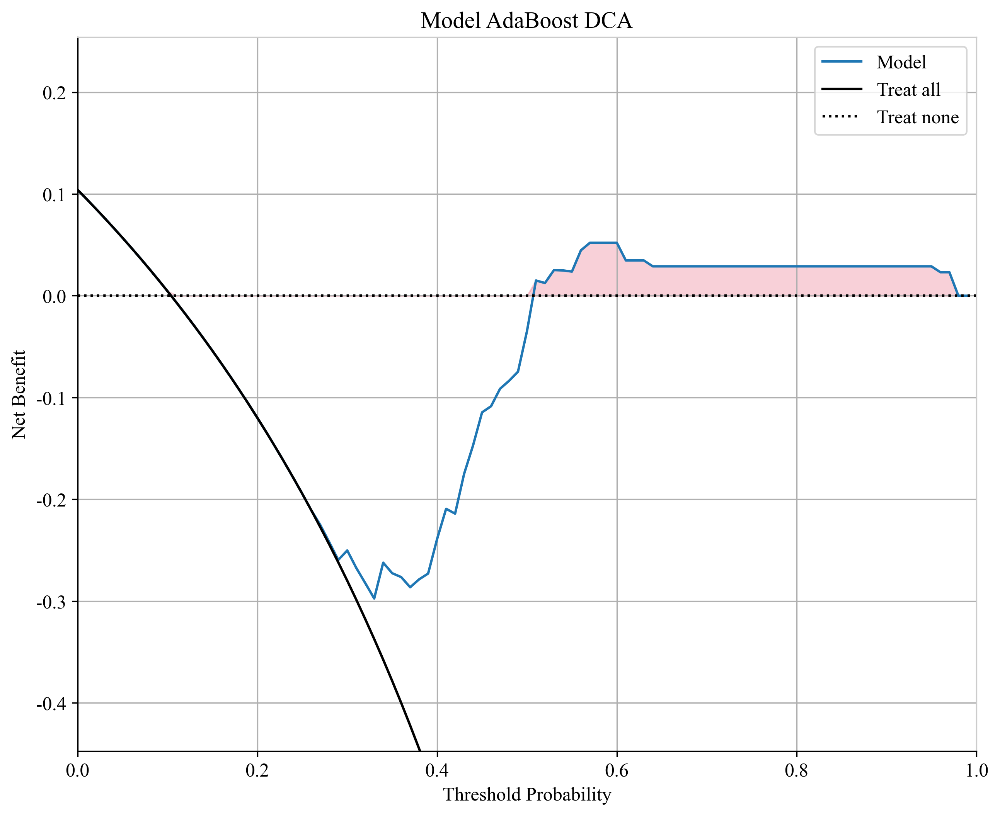

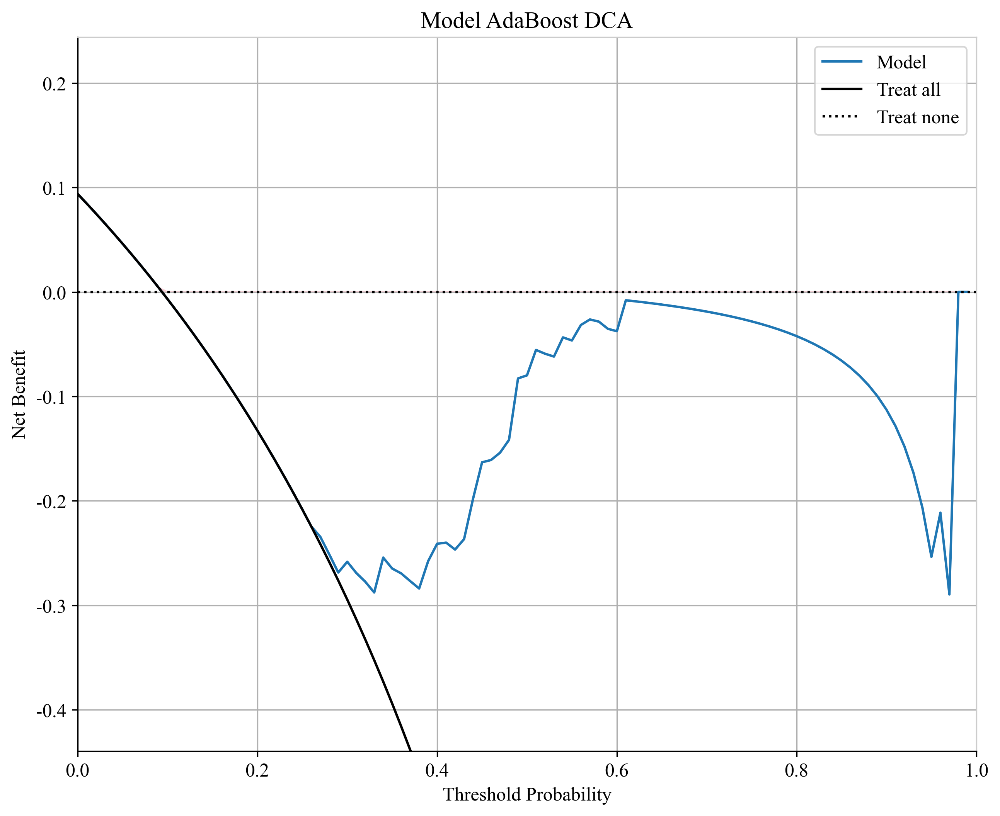

In [38]:
from onekey_algo.custom.components.comp1 import plot_DCA

for pred_score, label in zip(pred_scores, labels):
    pred_test_scores = []
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            okcomp.comp1.plot_DCA(pred_score[sel_model_idx][0][:,1], np.array(y_train_sel[label]),
                                  title=f'Model {sm} DCA')
            plt.savefig(f'img/{task_type}_model_{sm}_dca_train.svg', bbox_inches = 'tight')
            plt.show()
            # 绘制测试集
            sel_model_idx = model_names.index(sm)
            okcomp.comp1.plot_DCA(pred_score[sel_model_idx][1][:,1], np.array(y_test_sel[label]),
                                  title=f'Model {sm} DCA')
            plt.savefig(f'img/{task_type}_model_{sm}_dca_test.svg', bbox_inches = 'tight')

### 绘制混淆矩阵

绘制混淆矩阵，[混淆矩阵解释](https://baike.baidu.com/item/%E6%B7%B7%E6%B7%86%E7%9F%A9%E9%98%B5/10087822?fr=aladdin)
`sel_model = ['SVM', 'KNN']`参数为想要绘制的模型对应的参数。

如果需要修改标签到名称的映射，修改`class_mapping={1:'1', 0:'0'}`

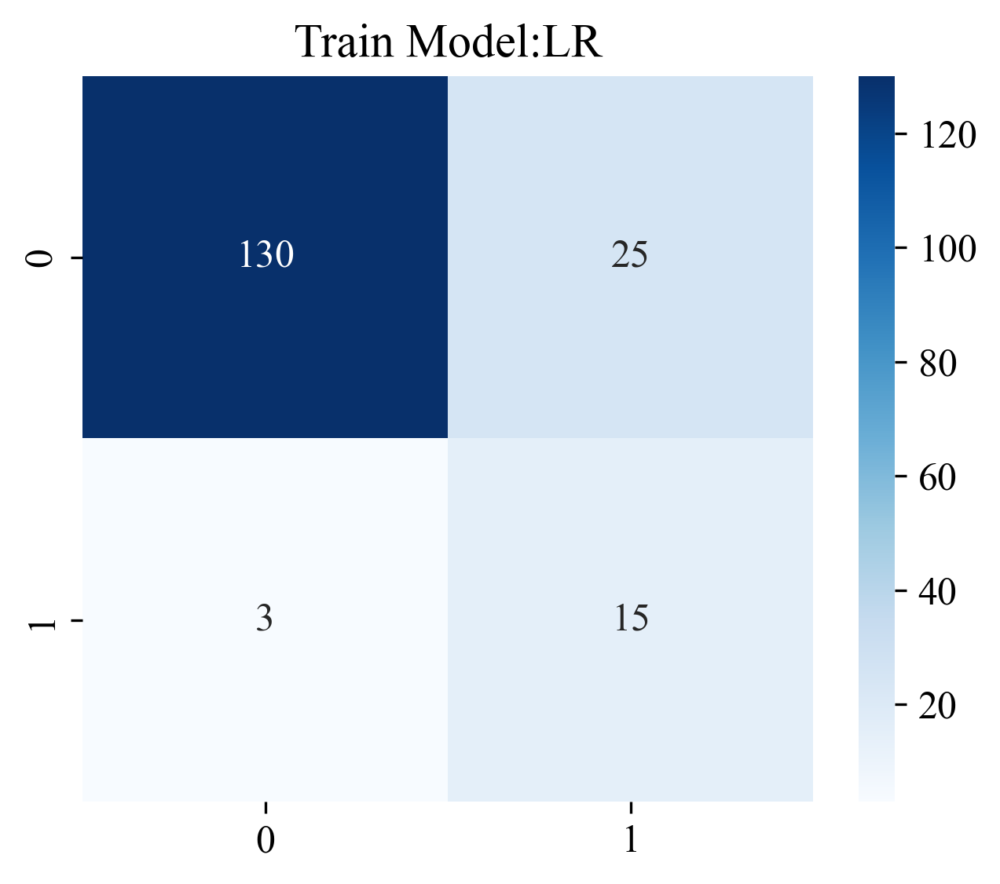

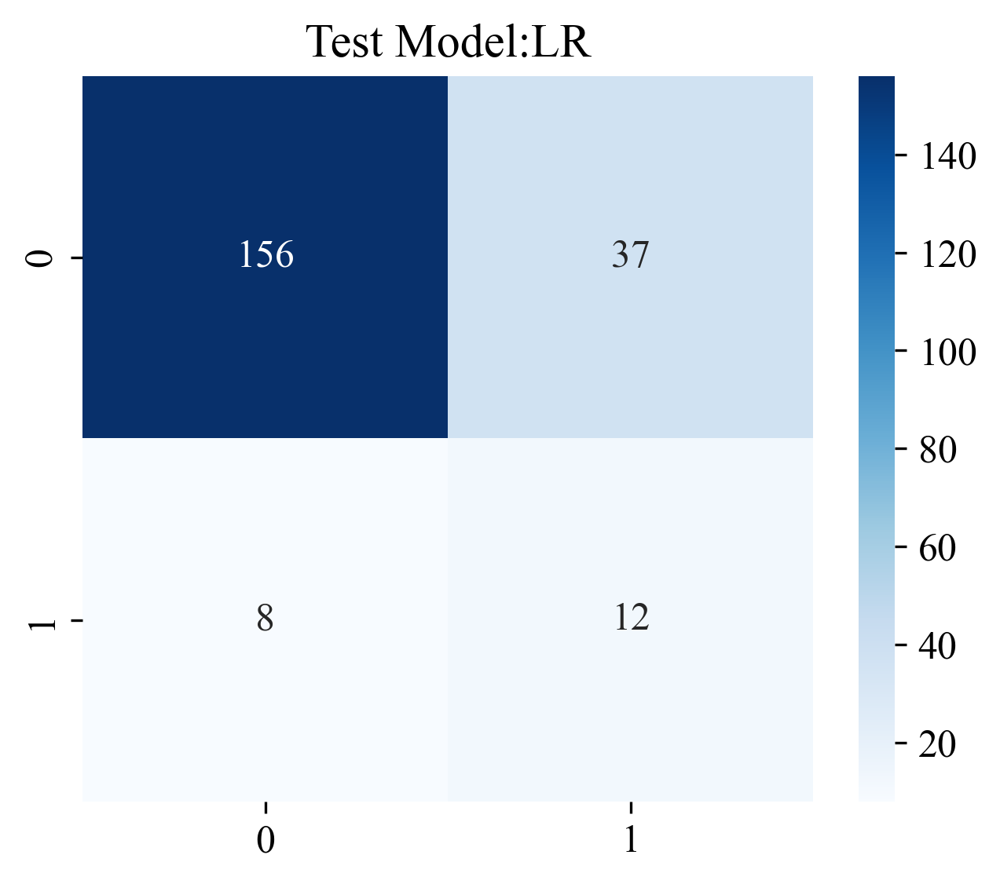

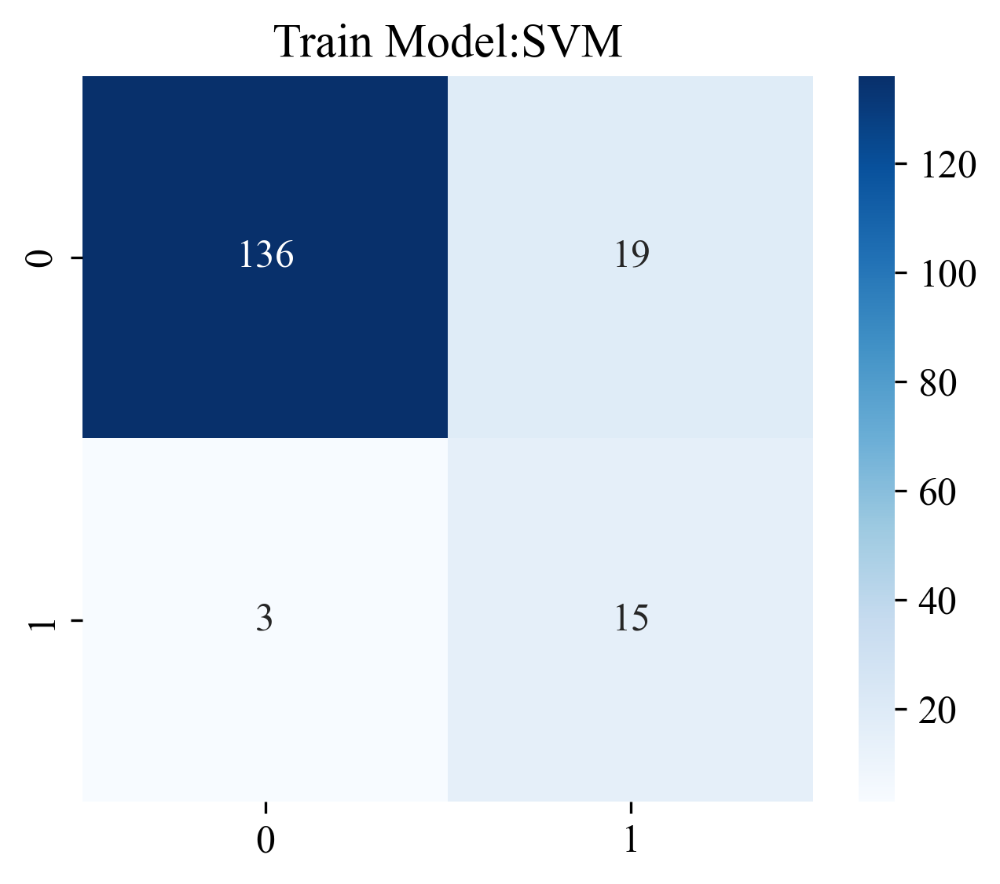

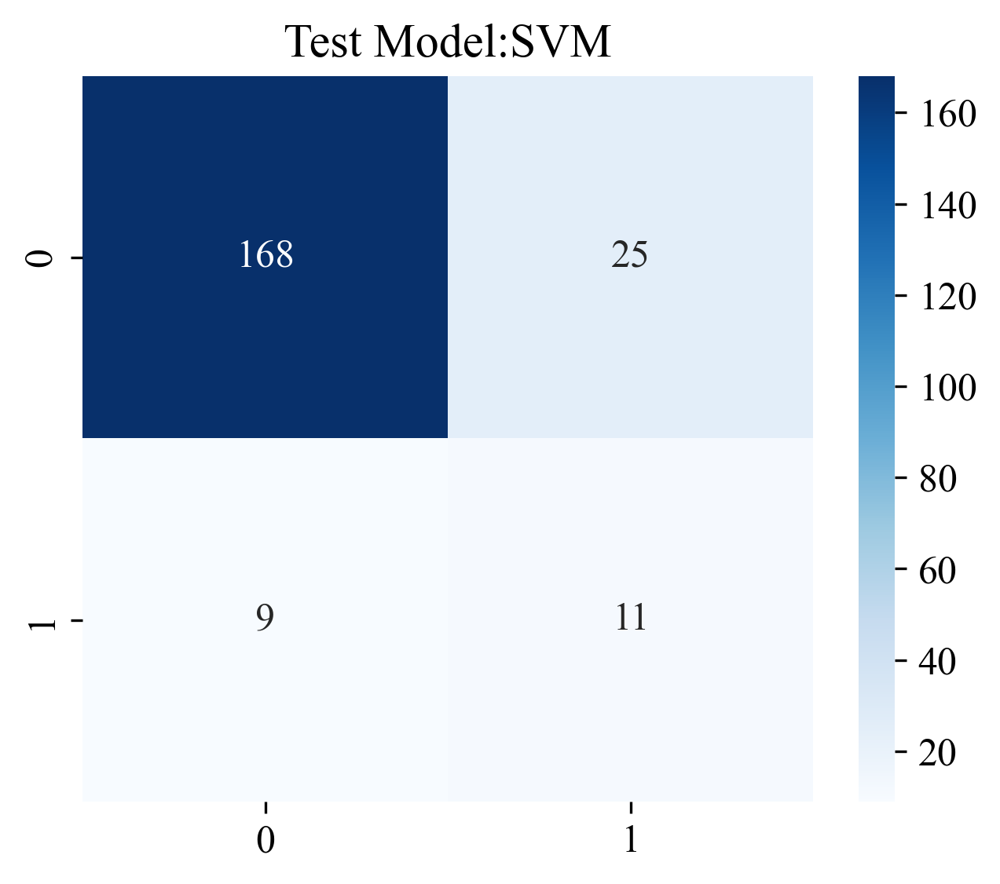

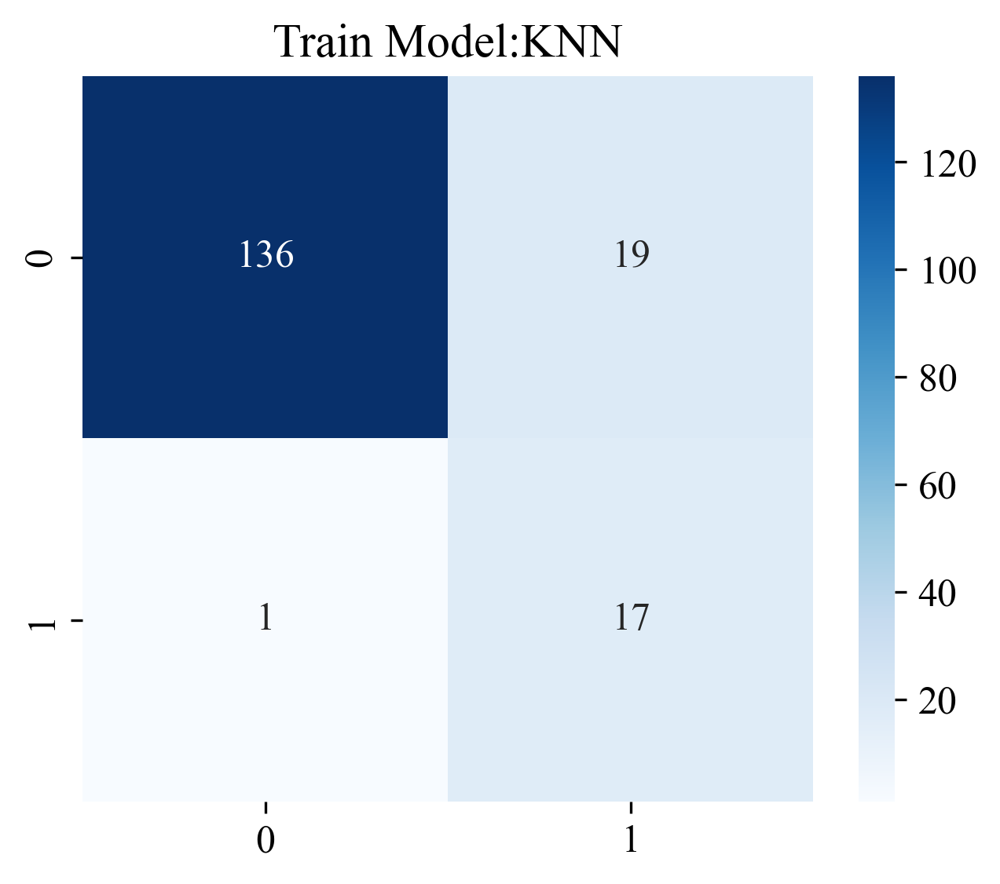

...

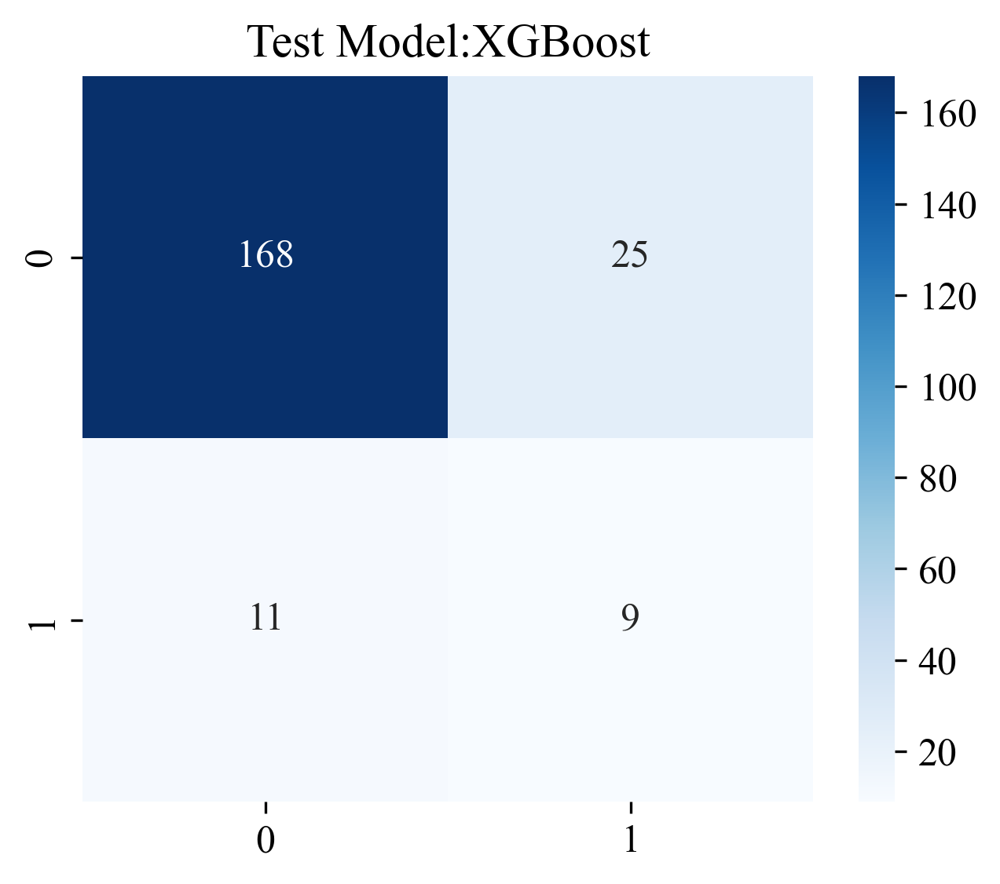

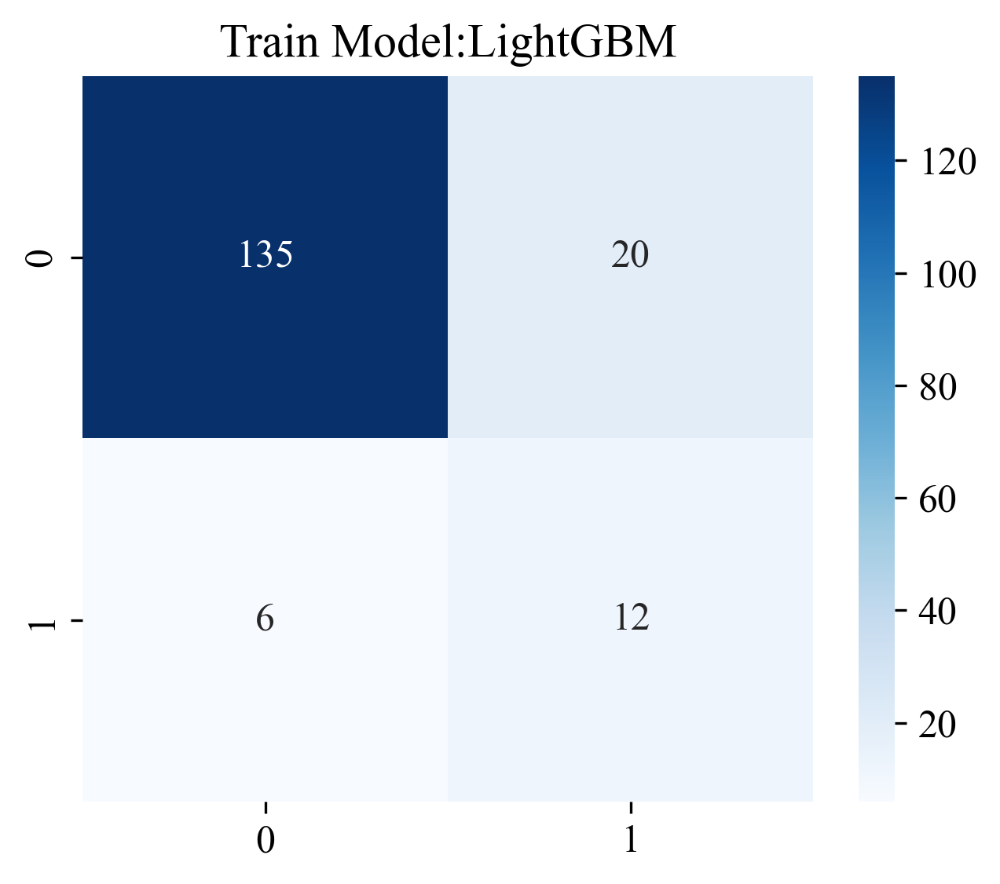

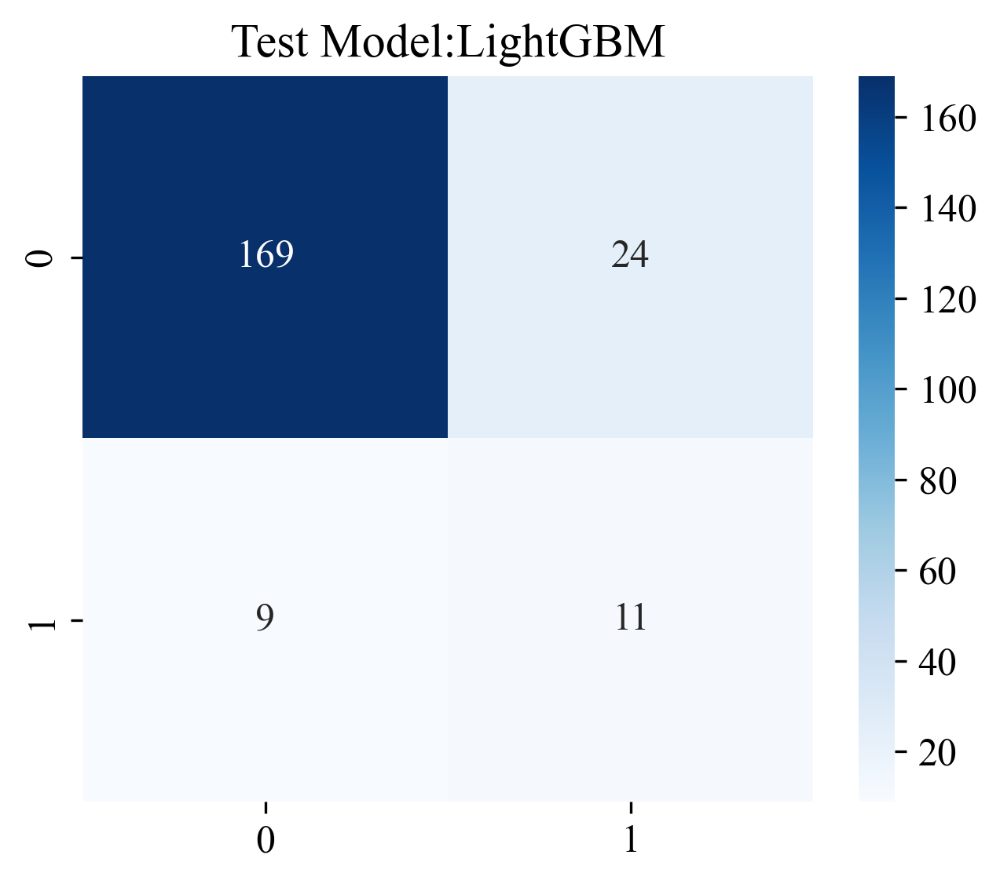

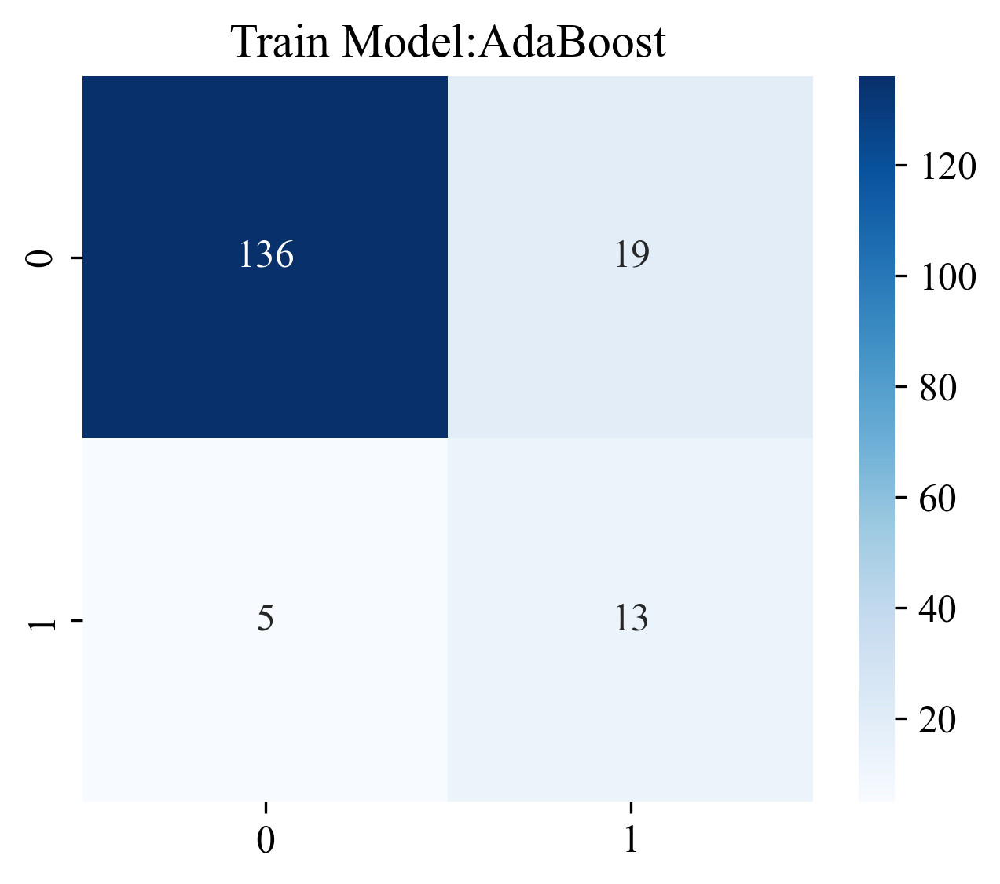

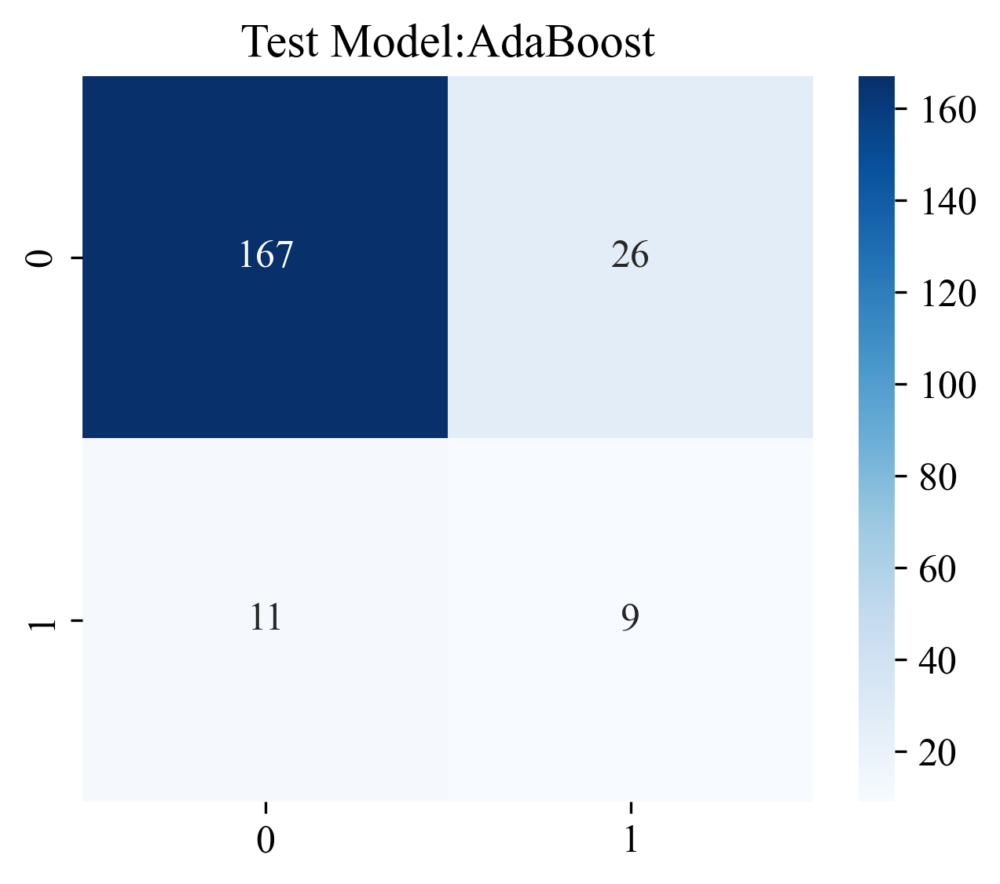

In [39]:
# 设置绘制参数
sel_model = model_names
c_matrix = {}

for sm in sel_model:
    if sm in model_names:
        sel_model_idx = model_names.index(sm)
        for idx, label in enumerate(labels):
            cm = okcomp.comp1.calc_confusion_matrix(predictions[idx][sel_model_idx][0], y_train_sel[label],
#                                                     sel_idx = pred_sel_idx[idx][sel_model_idx],
                                                    class_mapping={1:'1', 0:'0'}, num_classes=2)
            c_matrix[label] = cm
            plt.figure(figsize=(5, 4))
            plt.title(f'Train Model:{sm}')
            okcomp.comp1.draw_matrix(cm, norm=False, annot=True, cmap='Blues', fmt='.3g')
            plt.savefig(f'img/{task_type}_model_{sm}_cm_train.svg', bbox_inches = 'tight')
            plt.show()
            # 绘制测试集
            cm = okcomp.comp1.calc_confusion_matrix(predictions[idx][sel_model_idx][-1], y_test_sel[label],
#                                                     sel_idx = pred_sel_idx[idx][sel_model_idx],
                                                    class_mapping={1:'1', 0:'0'}, num_classes=2)
            c_matrix[label] = cm
            plt.figure(figsize=(5, 4))
            plt.title(f'Test Model:{sm}')
            okcomp.comp1.draw_matrix(cm, norm=False, annot=True, cmap='Blues', fmt='.3g')
            plt.savefig(f'img/{task_type}_model_{sm}_cm_test.svg', bbox_inches = 'tight')

### 样本预测直方图

绘制每个样本的预测结果以及对应的真实结果, 图例中label=xx可以修改成自己类别的真实标签。

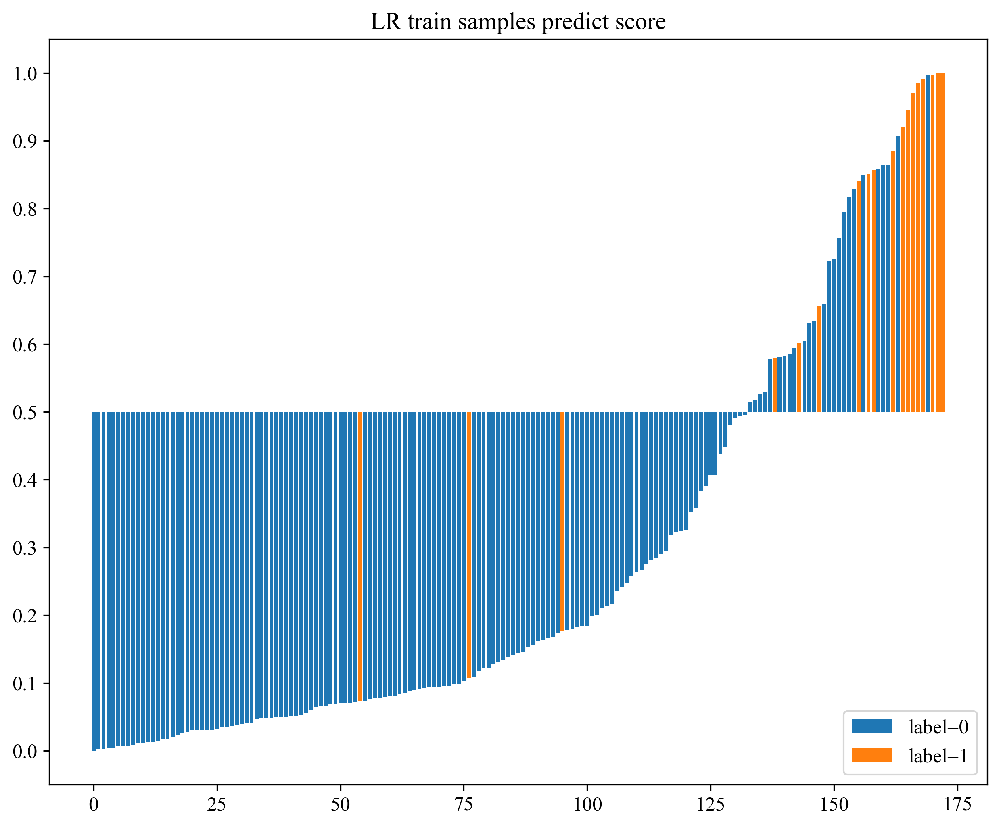

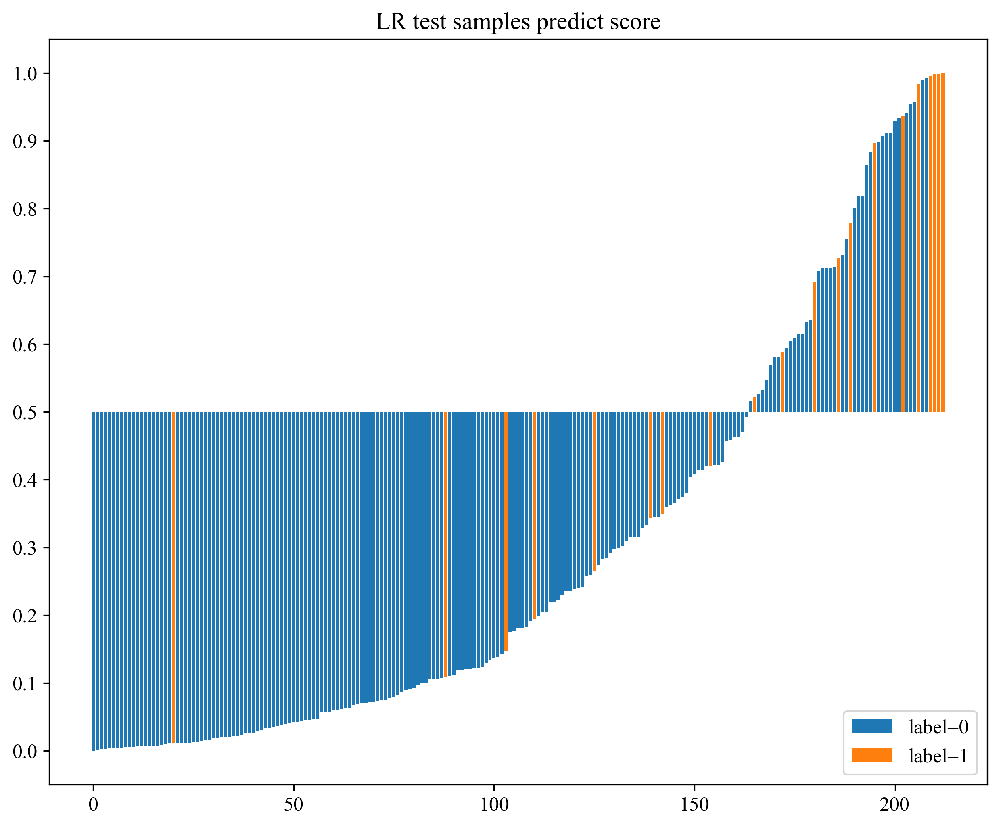

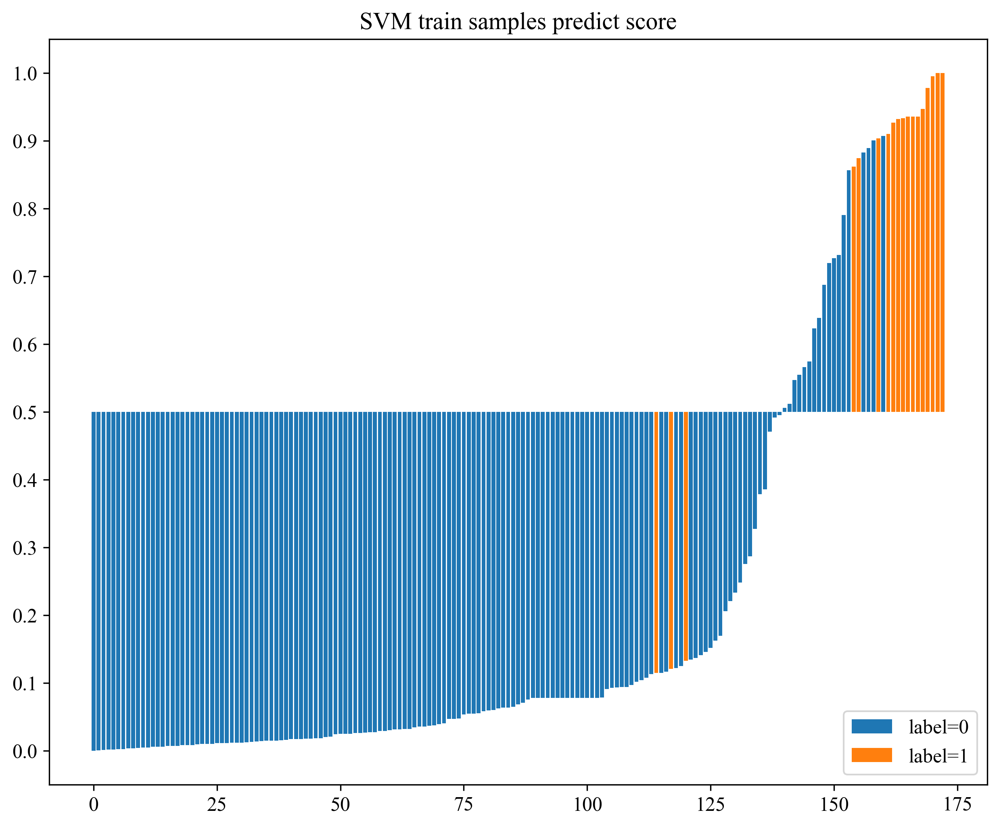

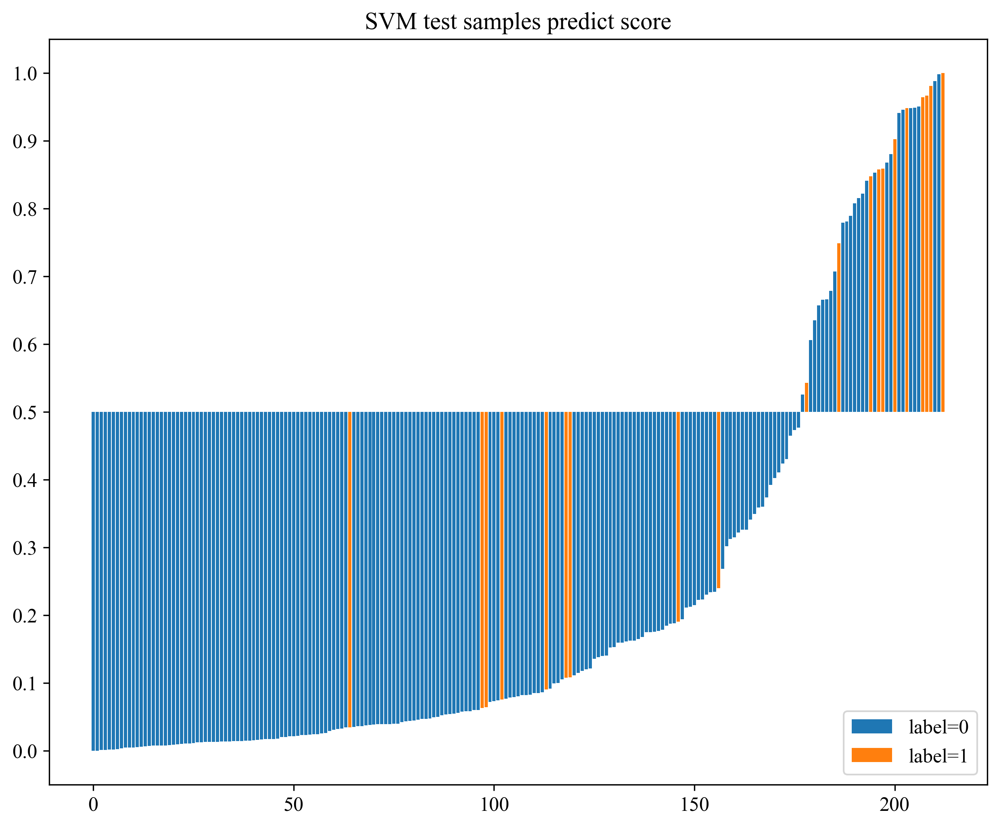

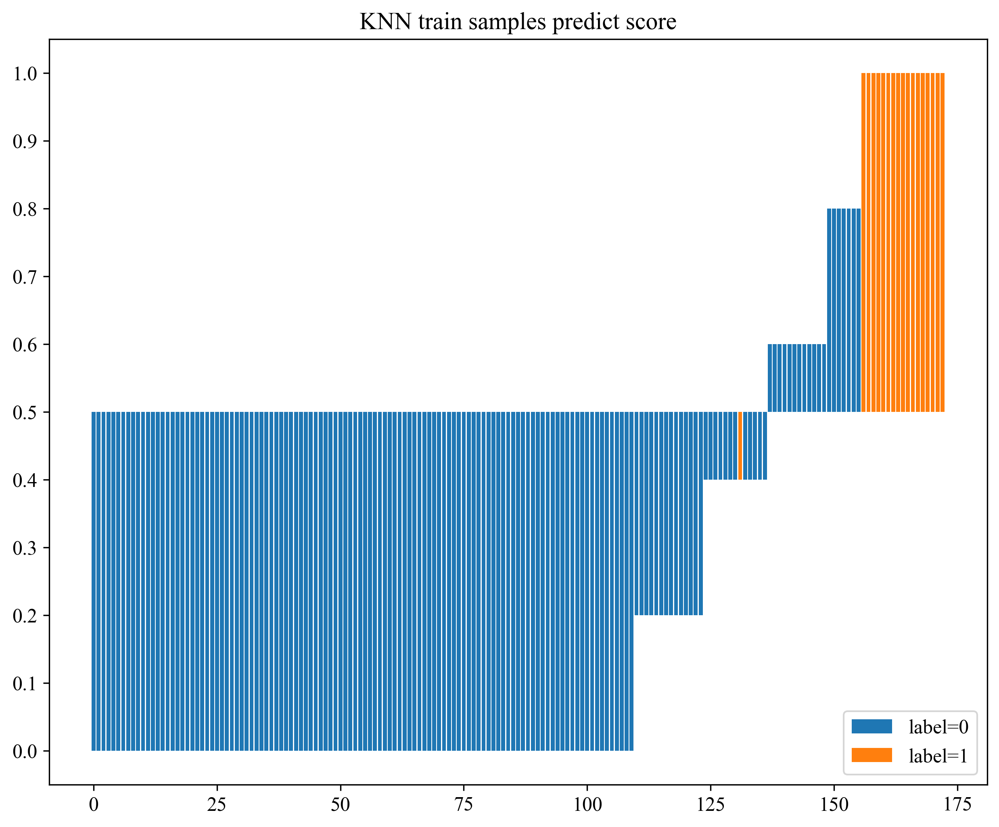

...

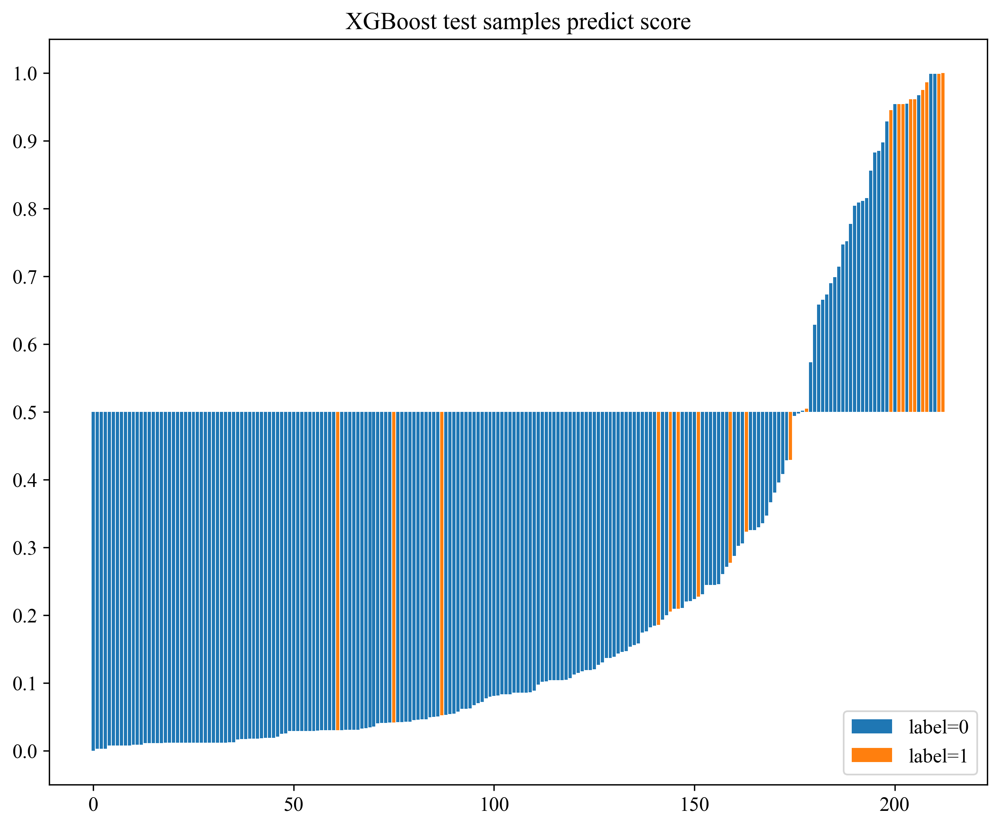

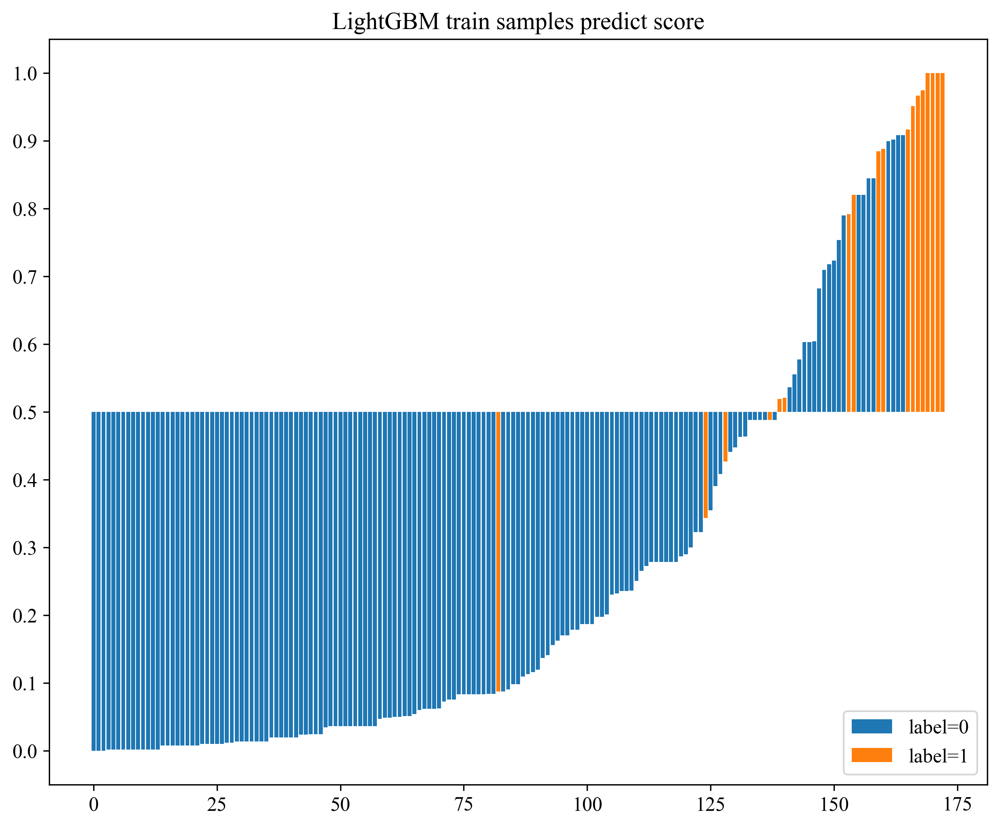

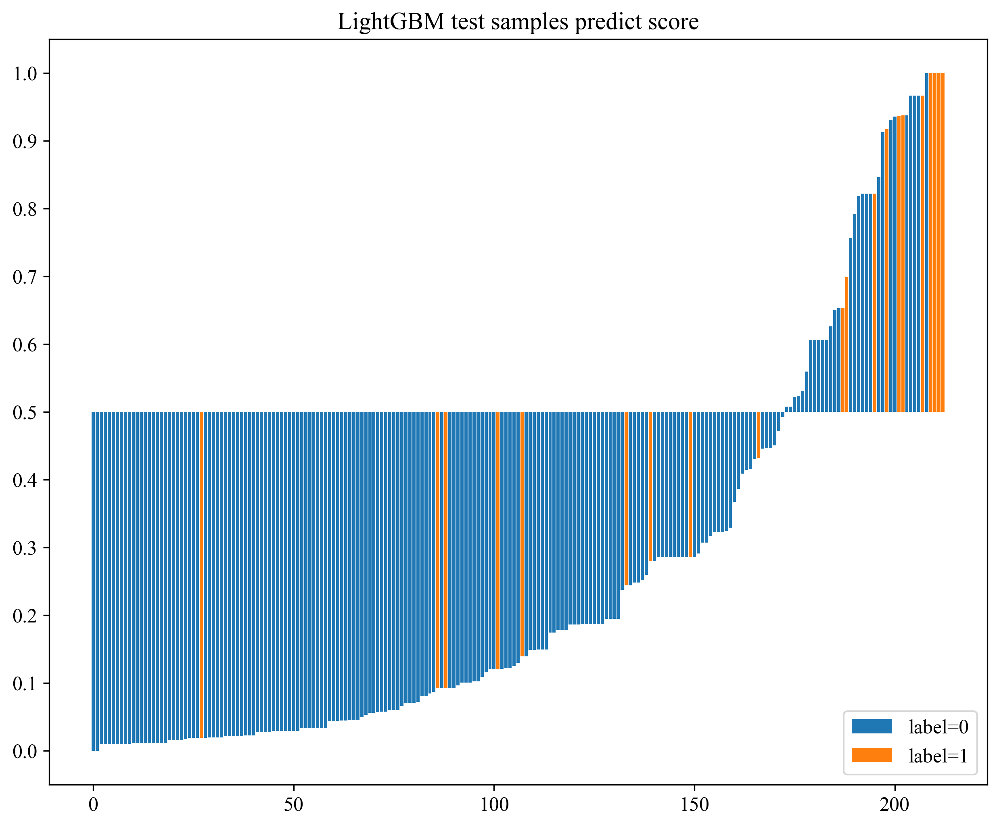

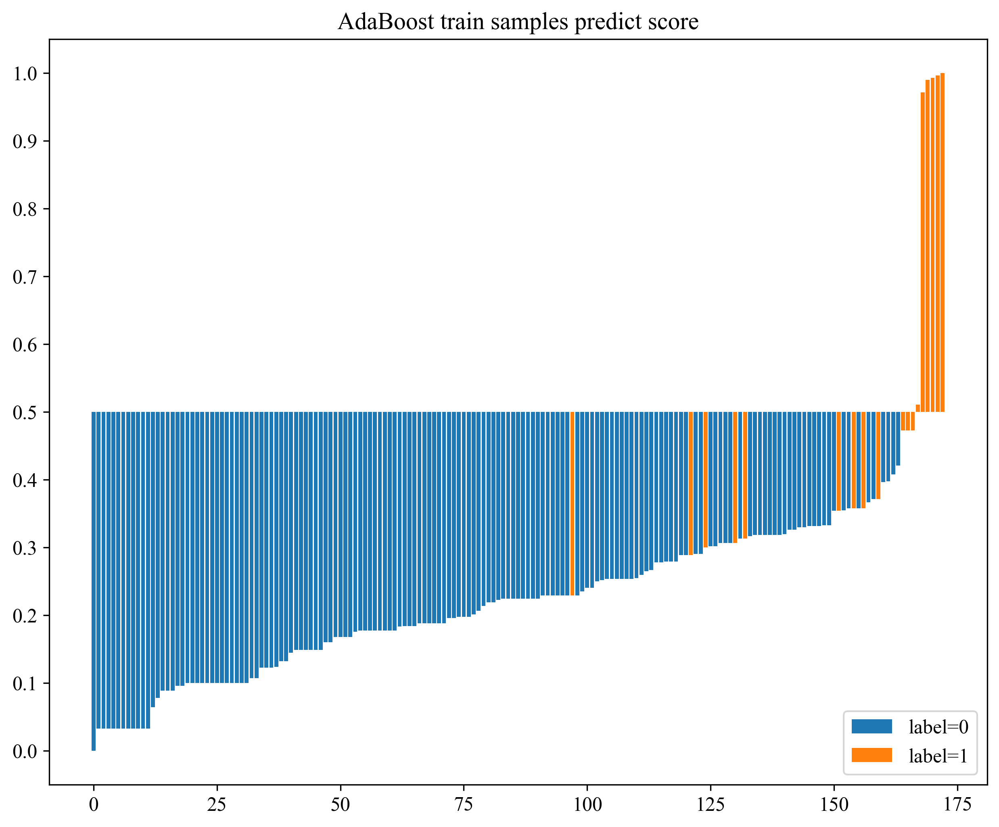

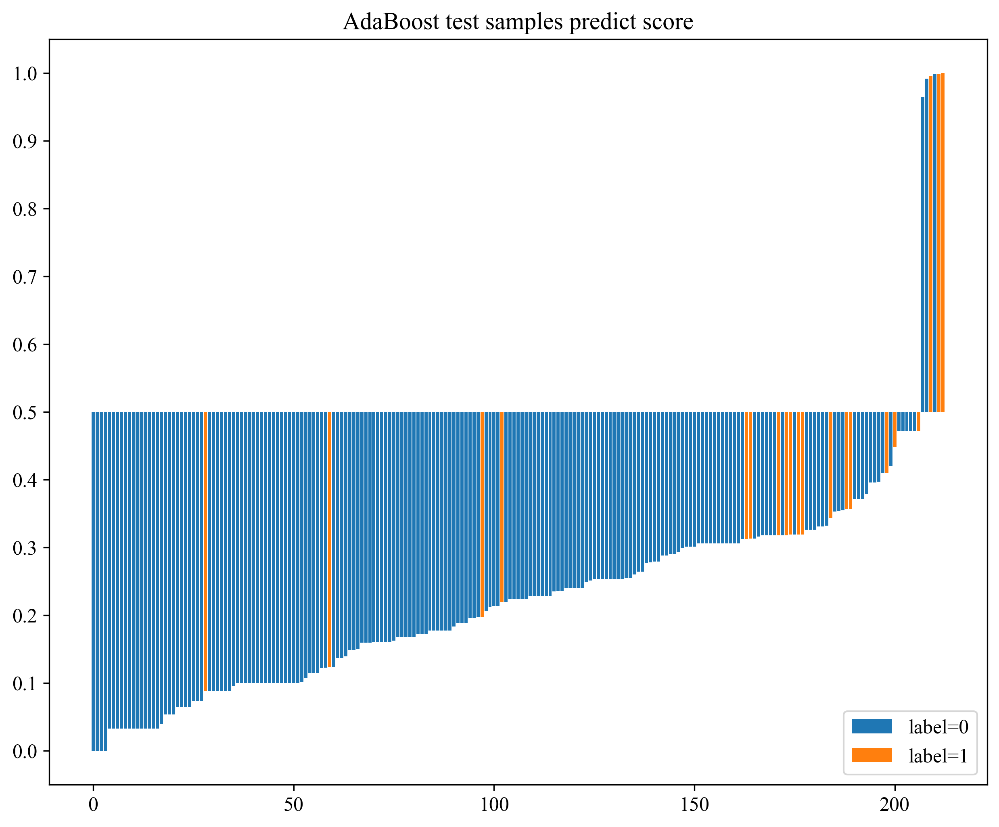

In [40]:
sel_model = model_names
c_matrix = {}

for sm in sel_model:
    if sm in model_names:
        sel_model_idx = model_names.index(sm)
        for idx, label in enumerate(labels):            
            okcomp.comp1.draw_predict_score(pred_scores[idx][sel_model_idx][0], y_train_sel[label])
            plt.title(f'{sm} train samples predict score')
            plt.legend(labels=["label=0","label=1"],loc="lower right") 
            plt.savefig(f'img/{task_type}_model_{sm}_sample_dis_train.svg', bbox_inches = 'tight')
            plt.show()
            # 绘制测试集
            okcomp.comp1.draw_predict_score(pred_scores[idx][sel_model_idx][-1], y_test_sel[label])
            plt.title(f'{sm} test samples predict score')
            plt.legend(labels=["label=0","label=1"],loc="lower right") 
            plt.savefig(f'img/{task_type}_model_{sm}_sample_dis_test.svg', bbox_inches = 'tight')
            plt.show()

## 保存模型结果

可以把模型预测的标签结果以及每个类别的概率都保存下来。

In [41]:
import os
import numpy as np

os.makedirs('results', exist_ok=True)
sel_model = sel_model

for idx, label in enumerate(labels):
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            target = targets[idx][sel_model_idx]
            # 预测训练集和测试集数据。
            train_indexes = np.reshape(np.array(train_ids), (-1, 1)).astype(str)
            test_indexes = np.reshape(np.array(test_ids), (-1, 1)).astype(str)
            y_train_pred_scores = target.predict_proba(X_train_sel)
            y_test_pred_scores = target.predict_proba(X_test_sel)
            columns = ['ID'] + [f"{label}-{i}"for i in range(y_test_pred_scores.shape[1])]
            # 保存预测的训练集和测试集结果
            result_train = pd.DataFrame(np.concatenate([train_indexes, y_train_pred_scores], axis=1), 
                                        columns=columns)
            result_train.to_csv(f'results/{task_type}_{sm}_train.csv', index=False)
            result_test = pd.DataFrame(np.concatenate([test_indexes, y_test_pred_scores], axis=1), 
                                       columns=columns)
            result_test.to_csv(f'results/{task_type}_{sm}_test.csv', index=False)
            